<a href="https://colab.research.google.com/github/Harshini-Bhandary21/AIML_Theory_Assignments/blob/main/Harshini_AIML_theory_IA_assignment_3_Classification_Regression_GradientDescent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Good Health and Well-being: Machine Learning Classification and Regression

### Team members
* Harshini Ramdas Bhandary (PRN: 202401040151) (Roll no: 35)
* Parth Nandkishor Shingane (PRN: 202401040210) (Roll no: 51)
* Dhruv Prafull Bompilwar (PRN: 202401040200) (Roll no: 49)

Activity No. 1: Machine Learning Classification and Regression

In the first assignment we collected World Bank data for UN Sustainable Development Goal 3 (Good Health and Well-being), cleaned it and made new features from it. Here we use the same final file (sdg3_health_engineered.csv) to train models.

Every model in this notebook is built in two ways. First we use the ready-made scikit-learn version. Then we write the same algorithm ourselves with only NumPy and check that both give nearly the same answer. This way we can see what the library is really doing.

Parts of the notebook
* Part A: Classification with SVM, Decision Tree, KNN and Naive Bayes, using scikit-learn. We check accuracy, precision, recall, F1-score and loss, and compare the four models.
* Part B: The same four models written from scratch, and a check against the library results.
* Part C: Regression to predict the life expectancy of a country, using scikit-learn.
* Part D: Regression models written from scratch, and a check against the library results.
* Part E: Gradient Descent for Linear Regression, written from scratch and compared with the library.
* Part F: Final summary.

## 1. Setup and loading the data

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression, Ridge, Lasso, SGDRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, log_loss,
                             hinge_loss, confusion_matrix, roc_curve, roc_auc_score,
                             mean_absolute_error, mean_squared_error, r2_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


def show(frame, digits=4):
    # prints a dataframe as simple lines of text, one line for each row
    for name, row in frame.iterrows():
        parts = []
        for col, val in row.items():
            if isinstance(val, (float, np.floating)):
                parts.append(f"{col} = {val:.{digits}f}")
            else:
                parts.append(f"{col} = {val}")
        print(f"{name}:  " + ",  ".join(parts))

The notebook needs the file sdg3_health_engineered.csv from the first assignment. Keep it in the same folder as this notebook. On Google Colab, if the file is missing, the next cell will ask you to upload it.

In [2]:
CSV_NAME = "sdg3_health_engineered.csv"

if not os.path.exists(CSV_NAME):
    try:
        from google.colab import files
        print("Please upload", CSV_NAME)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Put {CSV_NAME} in the same folder as this notebook.")

df = pd.read_csv(CSV_NAME)
print("Shape:", df.shape)
print("Countries:", df.country.nunique(), "| Years:", df.year.min(), "to", df.year.max())
print("Missing values left:", int(df.isna().sum().sum()))

Shape: (11915, 64)
Countries: 217 | Years: 1970 to 2024
Missing values left: 0


## 2. Choosing the input columns

We want to guess the health result of a country from things a government can measure: money spent on health, number of doctors and beds, clean water, income, vaccination and so on. So these columns are our inputs (X).

* health_expenditure_pct_gdp, log_health_exp_pc: money spent on health
* physicians_per_1000, hospital_beds_per_1000: doctors and beds
* basic_sanitation_pct, basic_drinking_water_pct: toilets and clean water
* measles_immunization_pct: vaccination
* log_gdp_per_capita, unemployment_pct, urban_population_pct, log_population: income, jobs and population
* birth_rate_per_1000: birth rate
* years_since_1970: the time trend

We left some columns out on purpose. These are infant_mortality_per_1000, death_rate_per_1000, life_exp_rolling5, life_exp_yoy_change, life_exp_equal_width, country_target_enc and similar ones. They are either another health result or they are made directly from life expectancy. If we kept them, the model would just copy the answer and the scores would look great without meaning anything. This problem is called data leakage.

In [3]:
FEATURES = [
    "health_expenditure_pct_gdp", "log_health_exp_pc",
    "physicians_per_1000", "hospital_beds_per_1000",
    "basic_sanitation_pct", "basic_drinking_water_pct", "measles_immunization_pct",
    "log_gdp_per_capita", "unemployment_pct", "urban_population_pct", "log_population",
    "birth_rate_per_1000", "years_since_1970",
]
print(len(FEATURES), "input columns")
show(df[FEATURES].describe().T[["mean", "std", "min", "max"]], digits=2)

13 input columns
health_expenditure_pct_gdp:  mean = 5.93,  std = 1.87,  min = 2.04,  max = 12.74
log_health_exp_pc:  mean = 5.54,  std = 1.38,  min = 2.40,  max = 8.80
physicians_per_1000:  mean = 1.37,  std = 1.29,  min = 0.02,  max = 5.17
hospital_beds_per_1000:  mean = 3.75,  std = 3.09,  min = 0.25,  max = 14.60
basic_sanitation_pct:  mean = 78.35,  std = 24.98,  min = 8.70,  max = 100.00
basic_drinking_water_pct:  mean = 89.03,  std = 14.92,  min = 36.59,  max = 100.00
measles_immunization_pct:  mean = 71.13,  std = 26.64,  min = 5.00,  max = 99.00
log_gdp_per_capita:  mean = 7.96,  std = 1.65,  min = 4.78,  max = 11.41
unemployment_pct:  mean = 7.38,  std = 4.70,  min = 0.72,  max = 26.18
urban_population_pct:  mean = 54.29,  std = 25.17,  min = 8.09,  max = 100.00
log_population:  mean = 14.89,  std = 2.44,  min = 8.64,  max = 21.10
birth_rate_per_1000:  mean = 25.79,  std = 12.67,  min = 7.80,  max = 51.89
years_since_1970:  mean = 27.03,  std = 15.87,  min = 0.00,  max = 54.0

## 3. Train and test split

Our file has one row for every year of every country, and rows of the same country look very alike. If we split the rows at random, Afghanistan 1995 could land in training and Afghanistan 1996 in testing, and the test would be too easy.

So we split by country. Eighty percent of the countries go to training and the other twenty percent are kept aside and never seen while training. This tells us how the model does on a new country.

We also scale the columns here. Scaling means we change every column so that its average is 0 and its spread is 1. We do it by hand with the training data only, so nothing from the test data leaks in. The scikit-learn pipelines later do the same thing with StandardScaler.

In [4]:
groups = df["country"]
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(df, groups=groups))

train_df, test_df = df.iloc[train_idx], df.iloc[test_idx]
groups_train = groups.iloc[train_idx]

X_train, X_test = train_df[FEATURES].values, test_df[FEATURES].values

# scaling written by hand: (value - mean) / spread, using numbers from the training rows only
mu = X_train.mean(axis=0)
sd = X_train.std(axis=0)
Xtr = (X_train - mu) / sd
Xte = (X_test - mu) / sd

print("Training rows:", len(train_df), "from", train_df.country.nunique(), "countries")
print("Testing rows :", len(test_df), "from", test_df.country.nunique(), "countries")
print("Countries in both sets:", len(set(train_df.country) & set(test_df.country)))

Training rows: 9495 from 173 countries
Testing rows : 2420 from 44 countries
Countries in both sets: 0


# Part A: Classification with scikit-learn

## 4. The classification problem

Question: from health and money related columns, can we tell if a country in a given year has a good life expectancy?

We turn life expectancy into two groups.
* 1 means good: life expectancy is 70 years or more
* 0 means not good: life expectancy is less than 70 years

Seventy is close to the world average and is often used as a benchmark. It also splits our data into two groups of nearly the same size.

Share of the good class in train: 47.1%   in test: 47.8%


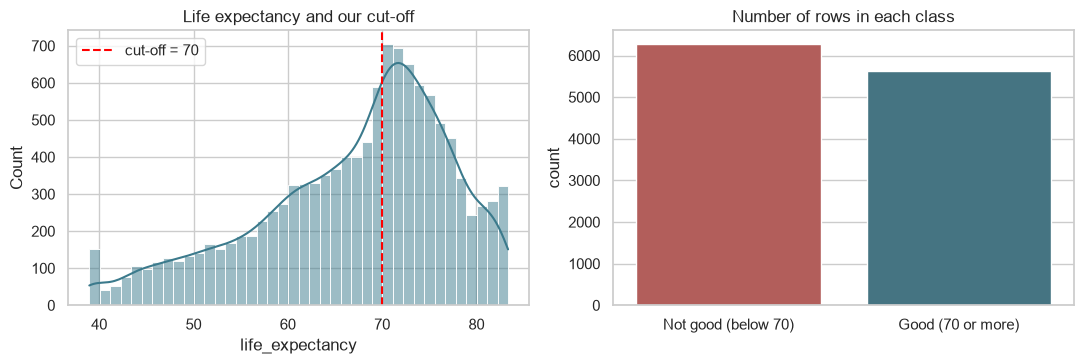

In [5]:
THRESHOLD = 70
y_train = (train_df["life_expectancy"] >= THRESHOLD).astype(int).values
y_test  = (test_df["life_expectancy"]  >= THRESHOLD).astype(int).values

print("Share of the good class in train: %.1f%%   in test: %.1f%%" % (y_train.mean()*100, y_test.mean()*100))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df["life_expectancy"], bins=40, kde=True, ax=ax[0], color="#3b7a8c")
ax[0].axvline(THRESHOLD, color="red", ls="--", label=f"cut-off = {THRESHOLD}")
ax[0].set_title("Life expectancy and our cut-off"); ax[0].legend()
sns.countplot(x=np.r_[y_train, y_test], ax=ax[1], palette=["#c0504d", "#3b7a8c"])
ax[1].set_xticklabels(["Not good (below 70)", "Good (70 or more)"]); ax[1].set_title("Number of rows in each class"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

The two classes are almost equal in size, so accuracy is a fair score here. We will still look at precision, recall, F1 and loss, as the assignment asks.

## 5. Training the four models with scikit-learn

Each model sits inside a Pipeline together with a StandardScaler. The scaler learns its numbers only from the training rows. Scaling is a must for SVM and KNN because they depend on distances. Decision Tree and Naive Bayes do not need it, but using the same setup for all four keeps the comparison fair.

We also try a few settings for each model with a grid search, and pick the best one. The cross-validation uses GroupKFold, so a country never appears in two folds.

* SVM with the RBF kernel: we try different values of C and gamma
* Decision Tree: we try max_depth and min_samples_leaf
* KNN: we try n_neighbors and weights
* Gaussian Naive Bayes: we try var_smoothing

In [6]:
models_and_grids = {
    "SVM": (SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
            {"clf__C": [0.5, 1, 5, 10], "clf__gamma": ["scale", 0.01, 0.05]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE),
            {"clf__max_depth": [3, 5, 7, 10, None], "clf__min_samples_leaf": [1, 5, 20]}),
    "KNN": (KNeighborsClassifier(),
            {"clf__n_neighbors": [3, 5, 9, 15, 25], "clf__weights": ["uniform", "distance"]}),
    "Naive Bayes": (GaussianNB(),
            {"clf__var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3, 1e-1]}),
}

cv = GroupKFold(n_splits=5)
best_models, train_times, best_params = {}, {}, {}

for name, (est, grid) in models_and_grids.items():
    pipe = Pipeline([("scale", StandardScaler()), ("clf", est)])
    search = GridSearchCV(pipe, grid, cv=cv, scoring="f1", n_jobs=-1)
    t0 = time.time()
    search.fit(X_train, y_train, groups=groups_train)
    train_times[name] = time.time() - t0
    best_models[name] = search.best_estimator_
    best_params[name] = search.best_params_
    print(f"{name:14s} best CV F1 = {search.best_score_:.4f} | best settings = {search.best_params_} | time = {train_times[name]:.1f}s")

SVM            best CV F1 = 0.8935 | best settings = {'clf__C': 0.5, 'clf__gamma': 0.05} | time = 13.3s


Decision Tree  best CV F1 = 0.8757 | best settings = {'clf__max_depth': 5, 'clf__min_samples_leaf': 1} | time = 0.4s


KNN            best CV F1 = 0.8793 | best settings = {'clf__n_neighbors': 25, 'clf__weights': 'uniform'} | time = 0.3s
Naive Bayes    best CV F1 = 0.8693 | best settings = {'clf__var_smoothing': 0.1} | time = 0.0s


## 6. Checking how good the models are

The scores we use, taking "good life expectancy" as the positive class:

* Accuracy: out of all predictions, how many were right.
* Precision: out of the countries the model called good, how many really are good.
* Recall: out of the countries that really are good, how many the model found.
* F1-score: one number that balances precision and recall.
* Loss (log loss): this looks at the probability the model gave, not only the final label. A model that is very sure and wrong gets a big penalty. Lower is better.
* ROC-AUC: an extra score that shows how well the model keeps the two classes apart.

We work out the scores for both training and test rows. If the training score is much higher than the test score, the model is overfitting, which means it learned the training rows too closely.

In [7]:
def classification_scores(model, X, y):
    pred = model.predict(X)
    prob = model.predict_proba(X)[:, 1]
    return {
        "Accuracy":  accuracy_score(y, pred),
        "Precision": precision_score(y, pred),
        "Recall":    recall_score(y, pred),
        "F1-score":  f1_score(y, pred),
        "Log loss":  log_loss(y, prob),
        "ROC-AUC":   roc_auc_score(y, prob),
    }

test_table  = pd.DataFrame({n: classification_scores(m, X_test,  y_test)  for n, m in best_models.items()}).T
train_table = pd.DataFrame({n: classification_scores(m, X_train, y_train) for n, m in best_models.items()}).T

print("Scores on the test rows (countries the models never saw)")
show(test_table)
print()
print("Scores on the training rows")
show(train_table)

Scores on the test rows (countries the models never saw)
SVM:  Accuracy = 0.9070,  Precision = 0.8895,  Recall = 0.9196,  F1-score = 0.9043,  Log loss = 0.2262,  ROC-AUC = 0.9672
Decision Tree:  Accuracy = 0.8748,  Precision = 0.8293,  Recall = 0.9291,  F1-score = 0.8764,  Log loss = 0.4902,  ROC-AUC = 0.9495
KNN:  Accuracy = 0.8686,  Precision = 0.8515,  Recall = 0.8780,  F1-score = 0.8646,  Log loss = 0.7670,  ROC-AUC = 0.9436
Naive Bayes:  Accuracy = 0.8843,  Precision = 0.8359,  Recall = 0.9429,  F1-score = 0.8862,  Log loss = 0.6452,  ROC-AUC = 0.9535

Scores on the training rows
SVM:  Accuracy = 0.9202,  Precision = 0.9007,  Recall = 0.9334,  F1-score = 0.9168,  Log loss = 0.1868,  ROC-AUC = 0.9792
Decision Tree:  Accuracy = 0.9284,  Precision = 0.9116,  Recall = 0.9390,  F1-score = 0.9251,  Log loss = 0.1900,  ROC-AUC = 0.9744
KNN:  Accuracy = 0.9402,  Precision = 0.9240,  Recall = 0.9513,  F1-score = 0.9374,  Log loss = 0.1367,  ROC-AUC = 0.9898
Naive Bayes:  Accuracy = 0.8763,

In [8]:
print("How much accuracy and F1 fall from training to test:")
for name in test_table.index:
    print(f"{name}:  accuracy falls by {train_table.loc[name, 'Accuracy'] - test_table.loc[name, 'Accuracy']:.4f},  F1 falls by {train_table.loc[name, 'F1-score'] - test_table.loc[name, 'F1-score']:.4f}")

How much accuracy and F1 fall from training to test:
SVM:  accuracy falls by 0.0131,  F1 falls by 0.0125
Decision Tree:  accuracy falls by 0.0536,  F1 falls by 0.0487
KNN:  accuracy falls by 0.0716,  F1 falls by 0.0729
Naive Bayes:  accuracy falls by -0.0080,  F1 falls by -0.0111


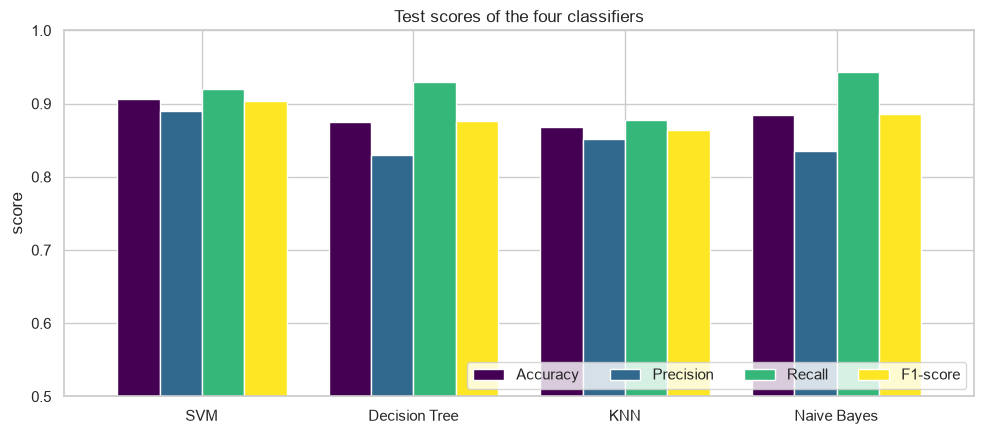

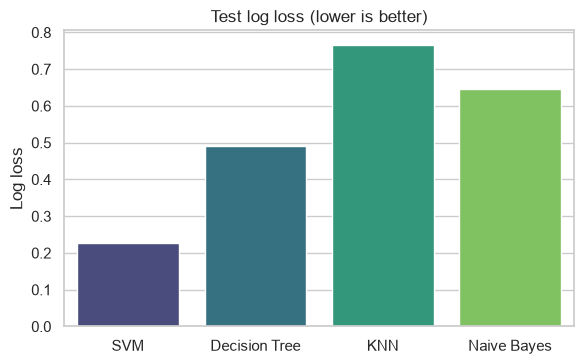

In [9]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
test_table[metrics].plot(kind="bar", figsize=(10, 4.5), width=0.8, colormap="viridis")
plt.ylim(0.5, 1.0); plt.xticks(rotation=0); plt.ylabel("score")
plt.title("Test scores of the four classifiers")
plt.legend(loc="lower right", ncol=4); plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 3.8))
sns.barplot(x=test_table.index, y=test_table["Log loss"], palette="viridis")
plt.title("Test log loss (lower is better)"); plt.xlabel(""); plt.tight_layout(); plt.show()

### 6.1 Confusion matrices

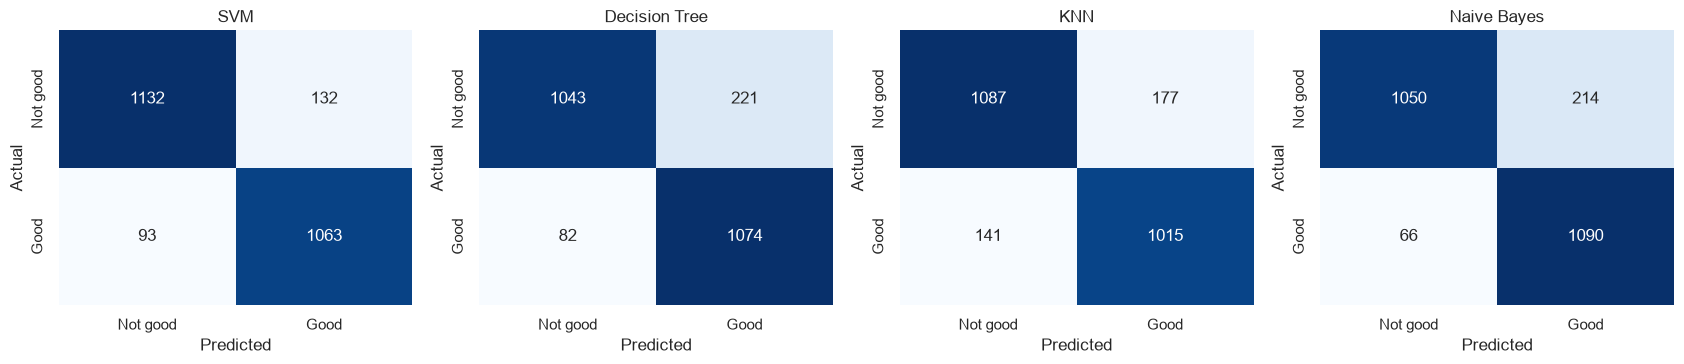

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, (name, model) in zip(axes, best_models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Not good", "Good"], yticklabels=["Not good", "Good"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

How to read it: the top right box holds the false positives, where the model said good but the country is not. The bottom left box holds the false negatives, where the model said not good but the country is actually good. Precision goes down because of the first kind of mistake, and recall goes down because of the second.

### 6.2 ROC curves

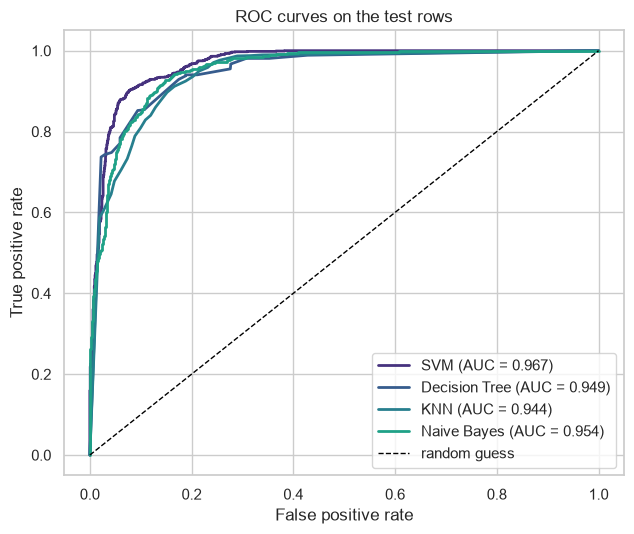

In [11]:
plt.figure(figsize=(6.5, 5.5))
for name, model in best_models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {test_table.loc[name, 'ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="random guess")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves on the test rows"); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

### 6.3 Is the result steady? (cross-validation)

One test split can be lucky or unlucky. So we also run 5-fold cross-validation on the training rows for each tuned model and look at the average F1 and how much it moves between folds.

SVM:  Mean F1 = 0.8935,  Std dev = 0.0221,  Worst fold = 0.8578,  Best fold = 0.9193
Decision Tree:  Mean F1 = 0.8757,  Std dev = 0.0254,  Worst fold = 0.8409,  Best fold = 0.9127
KNN:  Mean F1 = 0.8793,  Std dev = 0.0210,  Worst fold = 0.8445,  Best fold = 0.9049
Naive Bayes:  Mean F1 = 0.8693,  Std dev = 0.0338,  Worst fold = 0.8291,  Best fold = 0.9219


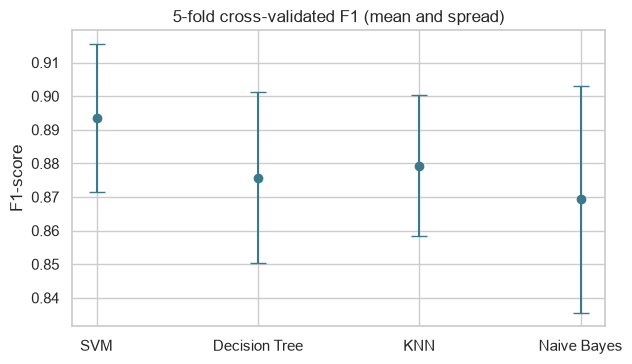

In [12]:
cv_table = {}
for name, model in best_models.items():
    s = cross_val_score(model, X_train, y_train, groups=groups_train, cv=cv, scoring="f1", n_jobs=-1)
    cv_table[name] = {"Mean F1": s.mean(), "Std dev": s.std(), "Worst fold": s.min(), "Best fold": s.max()}
cv_table = pd.DataFrame(cv_table).T
show(cv_table)

plt.figure(figsize=(6.5, 3.8))
plt.errorbar(cv_table.index, cv_table["Mean F1"], yerr=cv_table["Std dev"], fmt="o", capsize=6, color="#3b7a8c")
plt.ylabel("F1-score"); plt.title("5-fold cross-validated F1 (mean and spread)"); plt.tight_layout(); plt.show()

## 7. A closer look at each model

A few more checks to see why the models behave the way they do.

### 7.1 Decision Tree: the rules it learned

Chosen depth: 5 | number of leaves: 31


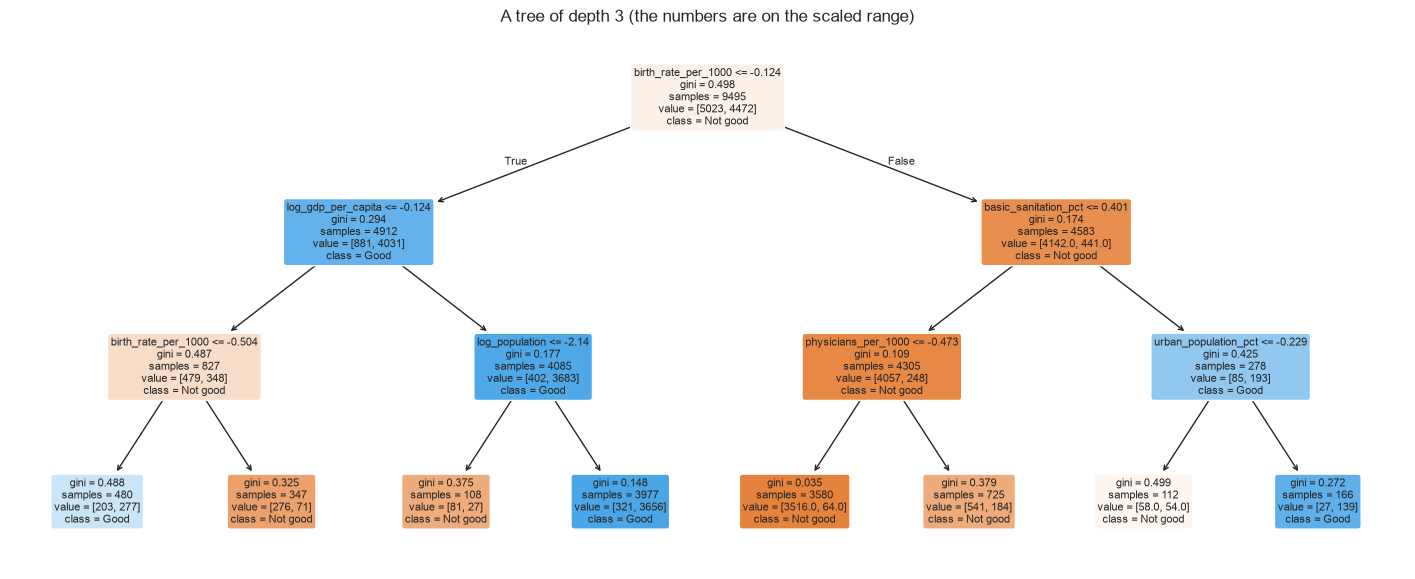

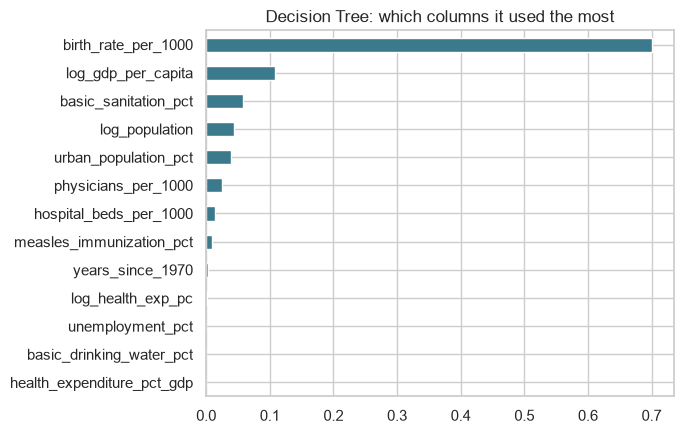

In [13]:
tree_model = best_models["Decision Tree"].named_steps["clf"]
print("Chosen depth:", tree_model.get_depth(), "| number of leaves:", tree_model.get_n_leaves())

# a small tree on the same data, only so that it is easy to read
small_tree = Pipeline([("scale", StandardScaler()), ("clf", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE))]).fit(X_train, y_train)
plt.figure(figsize=(18, 7))
plot_tree(small_tree.named_steps["clf"], feature_names=FEATURES, class_names=["Not good", "Good"],
          filled=True, rounded=True, fontsize=8)
plt.title("A tree of depth 3 (the numbers are on the scaled range)"); plt.show()

imp = pd.Series(tree_model.feature_importances_, index=FEATURES).sort_values()
imp.plot(kind="barh", figsize=(7, 4.5), color="#3b7a8c")
plt.title("Decision Tree: which columns it used the most"); plt.tight_layout(); plt.show()

### 7.2 KNN: what happens when k changes

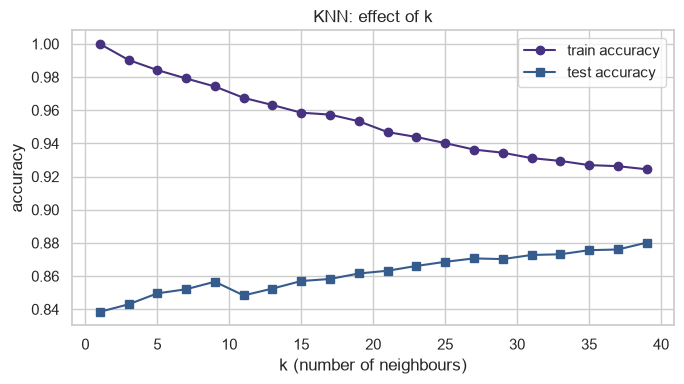

In [14]:
ks = list(range(1, 41, 2))
tr_acc, te_acc = [], []
for k in ks:
    m = Pipeline([("scale", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=k))]).fit(X_train, y_train)
    tr_acc.append(m.score(X_train, y_train)); te_acc.append(m.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(ks, tr_acc, "o-", label="train accuracy")
plt.plot(ks, te_acc, "s-", label="test accuracy")
plt.xlabel("k (number of neighbours)"); plt.ylabel("accuracy"); plt.title("KNN: effect of k")
plt.legend(); plt.tight_layout(); plt.show()

When k is very small, the model almost copies the training rows (train accuracy is close to 1) and the test accuracy is lower. This is overfitting. As k grows, the curve gets smoother and the gap becomes smaller.

### 7.3 Decision Tree: what happens when the depth changes

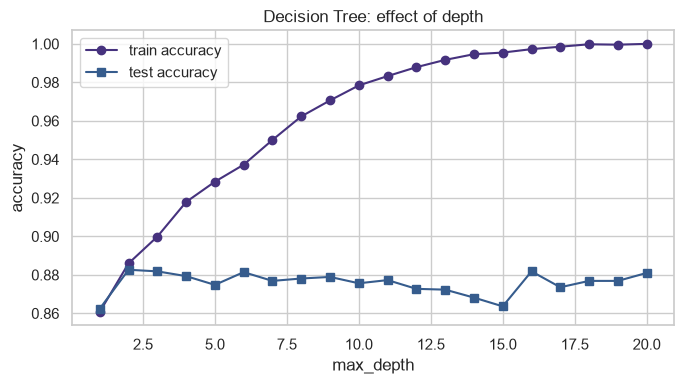

In [15]:
depths = list(range(1, 21))
tr_acc, te_acc = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    tr_acc.append(m.score(X_train, y_train)); te_acc.append(m.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(depths, tr_acc, "o-", label="train accuracy")
plt.plot(depths, te_acc, "s-", label="test accuracy")
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.title("Decision Tree: effect of depth")
plt.legend(); plt.tight_layout(); plt.show()

### 7.4 Naive Bayes: is its main idea true for our data?

Naive Bayes assumes that, once we know the class, the columns do not depend on each other. In health data this is not true. GDP, clean water and number of doctors all go up together. Let us see how strongly our columns are linked.

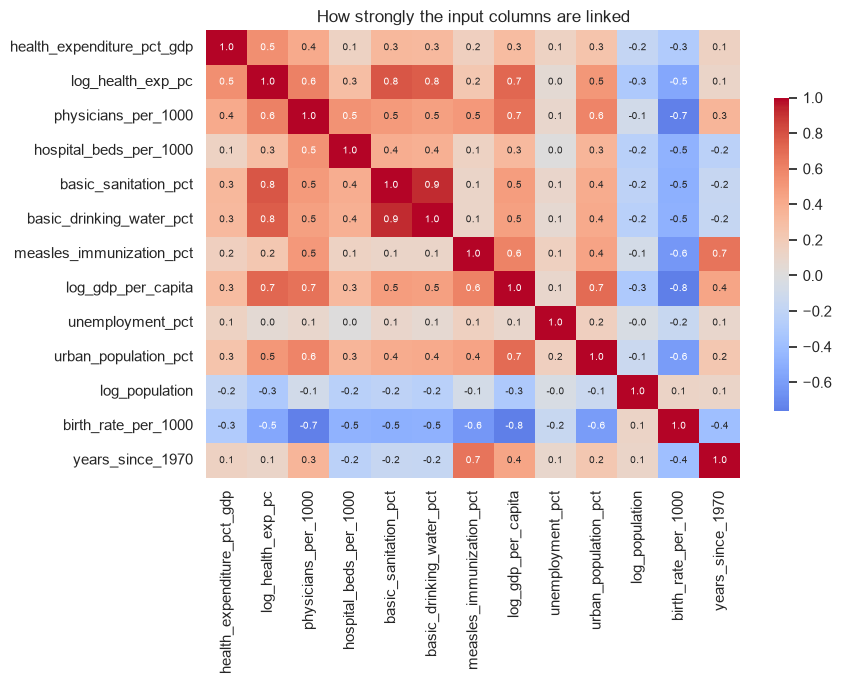

Pairs of columns with a link stronger than 0.7: 7 out of 169


In [16]:
corr = train_df[FEATURES].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7}, cbar_kws={"shrink": .7})
plt.title("How strongly the input columns are linked"); plt.tight_layout(); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("Pairs of columns with a link stronger than 0.7:", int((pairs.abs() > 0.7).sum()), "out of", len(pairs))

## 8. Comparing the four classifiers

In [17]:
summary = test_table.copy()
summary["Train time (s)"] = pd.Series(train_times)
show(summary)
print()
print("Best accuracy :", summary["Accuracy"].idxmax())
print("Best F1-score :", summary["F1-score"].idxmax())
print("Lowest loss   :", summary["Log loss"].idxmin())
print("Best ROC-AUC  :", summary["ROC-AUC"].idxmax())
print("Fastest       :", summary["Train time (s)"].idxmin())

SVM:  Accuracy = 0.9070,  Precision = 0.8895,  Recall = 0.9196,  F1-score = 0.9043,  Log loss = 0.2262,  ROC-AUC = 0.9672,  Train time (s) = 13.3279
Decision Tree:  Accuracy = 0.8748,  Precision = 0.8293,  Recall = 0.9291,  F1-score = 0.8764,  Log loss = 0.4902,  ROC-AUC = 0.9495,  Train time (s) = 0.3770
KNN:  Accuracy = 0.8686,  Precision = 0.8515,  Recall = 0.8780,  F1-score = 0.8646,  Log loss = 0.7670,  ROC-AUC = 0.9436,  Train time (s) = 0.3181
Naive Bayes:  Accuracy = 0.8843,  Precision = 0.8359,  Recall = 0.9429,  F1-score = 0.8862,  Log loss = 0.6452,  ROC-AUC = 0.9535,  Train time (s) = 0.0433

Best accuracy : SVM
Best F1-score : SVM
Lowest loss   : SVM
Best ROC-AUC  : SVM
Fastest       : Naive Bayes


### What the results tell us (test rows, countries the models never saw)

* SVM: accuracy 0.907, precision 0.890, recall 0.920, F1 0.904, log loss 0.226. Accuracy falls only 1.3 points from training to test.
* Decision Tree: accuracy 0.875, precision 0.829, recall 0.929, F1 0.876, log loss 0.490. Accuracy falls 5.4 points.
* KNN: accuracy 0.869, precision 0.852, recall 0.878, F1 0.865, log loss 0.767. Accuracy falls 7.2 points.
* Naive Bayes: accuracy 0.884, precision 0.836, recall 0.943, F1 0.886, log loss 0.645. The test accuracy is even a little higher than the training accuracy.

SVM is the best overall. It has the best accuracy, precision, F1 and ROC-AUC, and its loss is far lower than the others. It also does almost as well on new countries as on the ones it trained on. The only bad point is time: tuning it took about 13 seconds, while the others took less than half a second.

Naive Bayes has the best recall (0.943), so it finds almost every country that is really good. But its precision is low, so it also calls some not-good countries good. Its loss is high (0.645) even though its accuracy is fine. The reason is that it treats the columns as separate, but our columns move together (GDP, clean water, doctors). So it becomes too sure of itself, and log loss punishes a wrong answer given with high confidence. Its training and test scores are about the same, so it does not overfit, but it is also too simple to go much beyond 88%.

The Decision Tree is easy to read but a little shaky. Its recall is good (0.929) but its precision is the lowest (0.829). When we make the tree deeper, the training score keeps going up while the test accuracy stays around 0.87 to 0.88 (see the depth plot). So the extra depth only helps the tree remember the training rows. Its loss is high because a leaf can only give a few fixed probabilities, and when a leaf is wrong it is fully sure.

KNN is the weakest here. It has the lowest accuracy and F1, the highest loss, and the largest fall from training to test (7.2 points). KNN looks at the nearest rows, and in our data the nearest rows of a training country are its own other years. That makes training look easy. A new country has no such neighbours, so the test result is lower. A larger k helped a little (see the KNN plot) because the vote then comes from more countries.

About precision and recall: a false positive here means we said a country has good life expectancy when it does not. That could hide a country that needs help. SVM has the highest precision (0.890), so it makes the fewest of these mistakes. A false negative means we marked a good country as not good. If this is the worse mistake, then a model with high recall, such as Naive Bayes, is the safer choice.

About stability: in the 5-fold cross-validation all four F1 scores are within about 2.5 points of each other, and the spread between folds (0.02 to 0.03) is about as big as that gap. So the order of Decision Tree, KNN and Naive Bayes could change on a different split. SVM was first in the cross-validation and also first in the final test.

# Part B: The same four classifiers, written from scratch

Now we write the four algorithms ourselves with NumPy and no machine learning library. We give them the same scaled data and the same settings that the grid search chose above, so the two versions can be compared fairly.

We start with the scores themselves. We write accuracy, precision, recall, F1, log loss, hinge loss and ROC-AUC by hand and later use them to judge our own models.

## 9. Scores written by hand

In [18]:
def my_counts(y, p):
    tp = int(np.sum((y == 1) & (p == 1)))
    tn = int(np.sum((y == 0) & (p == 0)))
    fp = int(np.sum((y == 0) & (p == 1)))
    fn = int(np.sum((y == 1) & (p == 0)))
    return tp, tn, fp, fn

def my_accuracy(y, p):
    return np.mean(y == p)

def my_precision(y, p):
    tp, tn, fp, fn = my_counts(y, p)
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def my_recall(y, p):
    tp, tn, fp, fn = my_counts(y, p)
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def my_f1(y, p):
    pr, rc = my_precision(y, p), my_recall(y, p)
    return 2 * pr * rc / (pr + rc) if (pr + rc) > 0 else 0.0

def my_log_loss(y, prob):
    prob = np.clip(prob, 1e-15, 1 - 1e-15)          # stops log(0)
    return -np.mean(y * np.log(prob) + (1 - y) * np.log(1 - prob))

def my_hinge_loss(y, score):
    ys = np.where(y == 1, 1, -1)                     # hinge loss wants labels -1 and +1
    return np.mean(np.maximum(0, 1 - ys * score))

def my_roc_auc(y, score):
    # chance that a random good row gets a higher score than a random not-good row
    ranks = pd.Series(score).rank().values           # ties get the average rank
    n_pos, n_neg = int(y.sum()), int((1 - y).sum())
    return (ranks[y == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

def my_classification_scores(y, pred, prob):
    return {"Accuracy": my_accuracy(y, pred), "Precision": my_precision(y, pred), "Recall": my_recall(y, pred),
            "F1-score": my_f1(y, pred), "Log loss": my_log_loss(y, prob), "ROC-AUC": my_roc_auc(y, prob)}

A quick check: we feed the predictions of the library SVM to both our functions and the scikit-learn functions. If we wrote them right, the numbers must match.

In [19]:
svm_pred = best_models["SVM"].predict(X_test)
svm_prob = best_models["SVM"].predict_proba(X_test)[:, 1]
mine = my_classification_scores(y_test, svm_pred, svm_prob)
theirs = classification_scores(best_models["SVM"], X_test, y_test)
for k in mine:
    print(f"{k:10s} ours = {mine[k]:.6f}   scikit-learn = {theirs[k]:.6f}")

Accuracy   ours = 0.907025   scikit-learn = 0.907025
Precision  ours = 0.889540   scikit-learn = 0.889540
Recall     ours = 0.919550   scikit-learn = 0.919550
F1-score   ours = 0.904296   scikit-learn = 0.904296
Log loss   ours = 0.226201   scikit-learn = 0.226201
ROC-AUC    ours = 0.967213   scikit-learn = 0.967213


## 10. KNN from scratch

Idea: to label a new row, find the k training rows that are closest to it and let them vote. The distance is the normal straight line distance. For the probability we just take the share of neighbours that are good.

To make it fast we use the identity (a - b)^2 = a^2 + b^2 - 2ab for all pairs at once, instead of a slow loop.

In [20]:
class MyKNN:
    def __init__(self, k=5, task="classification"):
        self.k = k
        self.task = task

    def fit(self, X, y):
        self.X, self.y = X, y
        return self

    def _neighbour_values(self, Xq):
        out = []
        for s in range(0, len(Xq), 500):                         # small chunks so memory stays low
            q = Xq[s:s + 500]
            d = (q ** 2).sum(1)[:, None] + (self.X ** 2).sum(1)[None, :] - 2 * q @ self.X.T
            idx = np.argpartition(d, self.k - 1, axis=1)[:, :self.k]   # the k smallest distances
            out.append(self.y[idx])
        return np.vstack(out)

    def predict_proba(self, Xq):
        return self._neighbour_values(Xq).mean(axis=1)

    def predict(self, Xq):
        v = self._neighbour_values(Xq).mean(axis=1)
        return (v >= 0.5).astype(int) if self.task == "classification" else v

k_best = best_params["KNN"]["clf__n_neighbors"]
print("Using k =", k_best, "(from the grid search)")
t0 = time.time()
my_knn = MyKNN(k=k_best).fit(Xtr, y_train)
knn_prob = my_knn.predict_proba(Xte)
knn_pred = my_knn.predict(Xte)
print("Time taken: %.1f s" % (time.time() - t0))

Using k = 25 (from the grid search)
Time taken: 0.2 s


## 11. Naive Bayes from scratch

Idea: for every class we remember how common it is (the prior) and the average and spread of every column. For a new row, we find how likely its values are under each class using the bell curve (normal) formula, multiply the chances of all columns as if they were independent, multiply by the prior, and pick the class with the larger result.

Multiplying many small numbers can round down to zero, so we add their logarithms instead. For the final probability we use the softmax step, which turns the two log scores into two numbers that add up to 1.

var_smoothing adds a very small number to every spread so that we never divide by zero.

In [21]:
class MyGaussianNB:
    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        self.classes = np.unique(y)
        eps = self.var_smoothing * X.var(axis=0).max()
        self.mean = np.array([X[y == c].mean(axis=0) for c in self.classes])
        self.var = np.array([X[y == c].var(axis=0) for c in self.classes]) + eps
        self.prior = np.array([np.mean(y == c) for c in self.classes])
        return self

    def _log_scores(self, X):
        out = []
        for i in range(len(self.classes)):
            log_bell = -0.5 * np.sum(np.log(2 * np.pi * self.var[i]) + (X - self.mean[i]) ** 2 / self.var[i], axis=1)
            out.append(np.log(self.prior[i]) + log_bell)
        return np.array(out).T

    def predict_proba(self, X):
        s = self._log_scores(X)
        s = s - s.max(axis=1, keepdims=True)                 # keeps the numbers in a safe range
        p = np.exp(s)
        return p / p.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes[self._log_scores(X).argmax(axis=1)]

vs = best_params["Naive Bayes"]["clf__var_smoothing"]
print("Using var_smoothing =", vs)
my_nb = MyGaussianNB(var_smoothing=vs).fit(Xtr, y_train)
nb_prob = my_nb.predict_proba(Xte)[:, 1]
nb_pred = my_nb.predict(Xte)

Using var_smoothing = 0.1


## 12. Decision Tree from scratch

Idea: the tree asks a yes or no question about one column, for example "is birth rate below 25?", and splits the rows into two groups. It then does the same inside each group, again and again, until it hits the depth limit or a group is small or pure.

To pick the best question we try every column and every cut point and keep the one that makes the two groups the cleanest. For classification we measure the mess in a group with the Gini number, which is 2 x p x (1 - p), where p is the share of good rows (0 means perfectly clean). For regression later we use the variance of the target instead. The score of a split is the mean mess of the two groups, weighted by their sizes.

To try all cut points quickly, we sort the rows by the column and use running totals, so we do not have to recount the groups for every cut point.

Each leaf stores the average of the target in it. For classification that average is the share of good rows, which we use as the probability.

In [22]:
class MyDecisionTree:
    def __init__(self, task="classification", max_depth=5, min_samples_leaf=1):
        self.task = task
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf

    def _mess(self, n, s, s2):
        # n = size of group, s = sum of target, s2 = sum of squared target
        if self.task == "classification":
            p = s / n
            return 2 * p * (1 - p)                  # gini
        return s2 / n - (s / n) ** 2                # variance

    def fit(self, X, y):
        self.root = self._grow(X, y.astype(float), 0)
        return self

    def _best_split(self, X, y):
        n = len(y)
        best_col, best_cut, best_score = None, None, np.inf
        left_size = np.arange(1, n)
        right_size = n - left_size
        for j in range(X.shape[1]):
            order = np.argsort(X[:, j], kind="stable")
            xs, ys = X[order, j], y[order]
            run_s, run_s2 = np.cumsum(ys), np.cumsum(ys ** 2)
            ok = (xs[1:] != xs[:-1]) & (left_size >= self.min_samples_leaf) & (right_size >= self.min_samples_leaf)
            if not ok.any():
                continue
            sl, sl2 = run_s[:-1], run_s2[:-1]
            sr, sr2 = run_s[-1] - sl, run_s2[-1] - sl2
            score = (left_size * self._mess(left_size, sl, sl2) + right_size * self._mess(right_size, sr, sr2)) / n
            score = np.where(ok, score, np.inf)
            i = int(np.argmin(score))
            if score[i] < best_score:
                best_col, best_cut, best_score = j, (xs[i] + xs[i + 1]) / 2, score[i]
        return best_col, best_cut, best_score

    def _grow(self, X, y, depth):
        node = {"value": y.mean()}
        mess_here = self._mess(len(y), y.sum(), (y ** 2).sum())
        too_deep = self.max_depth is not None and depth >= self.max_depth
        if too_deep or len(y) < 2 * self.min_samples_leaf or mess_here <= 1e-12:
            return node
        col, cut, score = self._best_split(X, y)
        if col is None or score >= mess_here - 1e-12:      # the split does not help
            return node
        go_left = X[:, col] <= cut
        node["col"], node["cut"] = col, cut
        node["left"] = self._grow(X[go_left], y[go_left], depth + 1)
        node["right"] = self._grow(X[~go_left], y[~go_left], depth + 1)
        return node

    def _predict_row(self, row):
        node = self.root
        while "col" in node:
            node = node["left"] if row[node["col"]] <= node["cut"] else node["right"]
        return node["value"]

    def predict_proba(self, X):
        return np.array([self._predict_row(r) for r in X])

    def predict(self, X):
        v = self.predict_proba(X)
        return (v >= 0.5).astype(int) if self.task == "classification" else v

    def count_leaves(self, node=None):
        node = self.root if node is None else node
        return 1 if "col" not in node else self.count_leaves(node["left"]) + self.count_leaves(node["right"])

depth_best = best_params["Decision Tree"]["clf__max_depth"]
leaf_best = best_params["Decision Tree"]["clf__min_samples_leaf"]
print("Using max_depth =", depth_best, "and min_samples_leaf =", leaf_best)
t0 = time.time()
my_tree = MyDecisionTree("classification", depth_best, leaf_best).fit(Xtr, y_train)
tree_prob = my_tree.predict_proba(Xte)
tree_pred = my_tree.predict(Xte)
print("Leaves in our tree:", my_tree.count_leaves(), "| scikit-learn tree:", tree_model.get_n_leaves(), "| time taken: %.1f s" % (time.time() - t0))

Using max_depth = 5 and min_samples_leaf = 1


Leaves in our tree: 31 | scikit-learn tree: 31 | time taken: 0.0 s


## 13. SVM from scratch

A full SVM with the RBF kernel needs a quadratic programming solver, which is a lot of work to write by hand. So here we write the linear SVM, which draws a straight line (a flat plane in many columns) between the classes. We train it with gradient descent.

The cost we reduce has two parts. The hinge loss punishes rows that are on the wrong side of the line or too close to it. The second part keeps the weights small, which gives a wide gap between the classes:

cost = (lambda / 2) x (sum of w squared) + average of max(0, 1 - y x (w . x + b))

where y is -1 or +1. In every small step we take a mini-batch of rows. For the rows that break the rule (y x score below 1) the slope is -y x x. The step size gets smaller as we train.

To compare, we use the scikit-learn SVC with a linear kernel and the matching C value, which is C = 1 / (lambda x number of rows).

A linear SVM does not give probabilities by itself, so for it we report the hinge loss, which is the natural loss of an SVM.

Time taken: 0.1 s


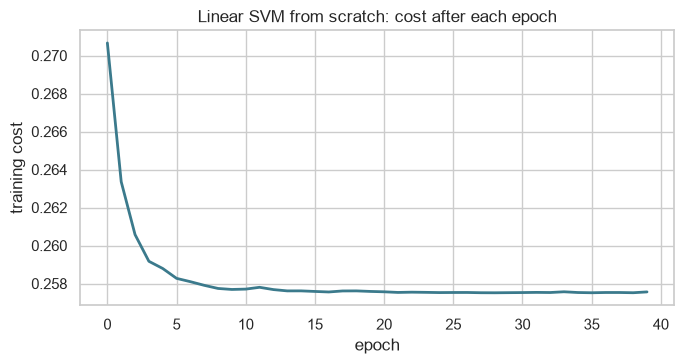

In [23]:
def train_linear_svm(X, y01, lam=0.001, epochs=40, batch=64, lr0=0.1, seed=0):
    rng = np.random.default_rng(seed)
    ys = np.where(y01 == 1, 1, -1)
    m, n = X.shape
    w, b, step = np.zeros(n), 0.0, 0
    cost_history = []
    for ep in range(epochs):
        order = rng.permutation(m)
        for s in range(0, m, batch):
            idx = order[s:s + batch]
            Xb, yb = X[idx], ys[idx]
            step += 1
            lr = lr0 / (1 + 0.001 * step)                     # smaller steps as time goes on
            broken = yb * (Xb @ w + b) < 1                    # rows that break the margin rule
            grad_w = lam * w - (yb[broken, None] * Xb[broken]).sum(axis=0) / len(idx)
            grad_b = -yb[broken].sum() / len(idx)
            w, b = w - lr * grad_w, b - lr * grad_b
        full_cost = 0.5 * lam * (w @ w) + np.mean(np.maximum(0, 1 - ys * (X @ w + b)))
        cost_history.append(full_cost)
    return w, b, cost_history

LAMBDA = 0.001
t0 = time.time()
w_svm, b_svm, svm_cost = train_linear_svm(Xtr, y_train, lam=LAMBDA)
print("Time taken: %.1f s" % (time.time() - t0))

svm_score = Xte @ w_svm + b_svm
svm_pred_scratch = (svm_score >= 0).astype(int)

plt.figure(figsize=(7, 3.8))
plt.plot(svm_cost, color="#3b7a8c", lw=2)
plt.xlabel("epoch"); plt.ylabel("training cost"); plt.title("Linear SVM from scratch: cost after each epoch")
plt.tight_layout(); plt.show()

C_value = 1 / (LAMBDA * len(Xtr))
lib_linear_svm = SVC(kernel="linear", C=C_value).fit(Xtr, y_train)
lib_svm_score = lib_linear_svm.decision_function(Xte)

## 14. Scratch models against the scikit-learn models

First the three models that have a probability (KNN, Naive Bayes, Decision Tree). For each we show the scratch scores next to the scikit-learn scores on the same test rows, and the share of rows where the two models gave the same label.

In [24]:
scratch_results = {
    "KNN":           (knn_pred,  knn_prob),
    "Naive Bayes":   (nb_pred,   nb_prob),
    "Decision Tree": (tree_pred, tree_prob),
}
for name, (pred, prob) in scratch_results.items():
    mine = my_classification_scores(y_test, pred, prob)
    lib = test_table.loc[name]
    same = np.mean(pred == best_models[name].predict(X_test))
    print(name)
    print("   scratch      :", ", ".join(f"{k} {v:.4f}" for k, v in mine.items()))
    print("   scikit-learn :", ", ".join(f"{k} {lib[k]:.4f}" for k in mine))
    print(f"   same label on {same*100:.1f}% of the test rows")

KNN
   scratch      : Accuracy 0.8686, Precision 0.8515, Recall 0.8780, F1-score 0.8646, Log loss 0.7446, ROC-AUC 0.9436
   scikit-learn : Accuracy 0.8686, Precision 0.8515, Recall 0.8780, F1-score 0.8646, Log loss 0.7670, ROC-AUC 0.9436
   same label on 100.0% of the test rows
Naive Bayes
   scratch      : Accuracy 0.8843, Precision 0.8359, Recall 0.9429, F1-score 0.8862, Log loss 0.6452, ROC-AUC 0.9535
   scikit-learn : Accuracy 0.8843, Precision 0.8359, Recall 0.9429, F1-score 0.8862, Log loss 0.6452, ROC-AUC 0.9535
   same label on 100.0% of the test rows
Decision Tree
   scratch      : Accuracy 0.8748, Precision 0.8293, Recall 0.9291, F1-score 0.8764, Log loss 0.4821, ROC-AUC 0.9495
   scikit-learn : Accuracy 0.8748, Precision 0.8293, Recall 0.9291, F1-score 0.8764, Log loss 0.4902, ROC-AUC 0.9495
   same label on 100.0% of the test rows


Now the SVM. Our scratch version is a linear SVM, so we compare it with the scikit-learn linear SVM (same kernel) and also with the RBF SVM that we tuned in Part A.

In [25]:
def svm_line(pred, score):
    return (f"Accuracy {my_accuracy(y_test, pred):.4f}, Precision {my_precision(y_test, pred):.4f}, Recall {my_recall(y_test, pred):.4f}, "
            f"F1-score {my_f1(y_test, pred):.4f}, Hinge loss {my_hinge_loss(y_test, score):.4f}, ROC-AUC {my_roc_auc(y_test, score):.4f}")

rbf_score = best_models["SVM"].decision_function(X_test)
print("Linear SVM, scratch      :", svm_line(svm_pred_scratch, svm_score))
print("Linear SVM, scikit-learn :", svm_line(lib_linear_svm.predict(Xte), lib_svm_score))
print("RBF SVM, scikit-learn    :", svm_line(best_models["SVM"].predict(X_test), rbf_score))
print()
print("Check of our hinge loss against scikit-learn:", round(my_hinge_loss(y_test, lib_svm_score), 6), "vs", round(hinge_loss(y_test, lib_svm_score), 6))
print("Largest difference between scratch and library weights:", np.abs(w_svm - lib_linear_svm.coef_[0]).max().round(3))

Linear SVM, scratch      : Accuracy 0.8930, Precision 0.8597, Recall 0.9273, F1-score 0.8922, Hinge loss 0.2474, ROC-AUC 0.9694
Linear SVM, scikit-learn : Accuracy 0.8926, Precision 0.8590, Recall 0.9273, F1-score 0.8918, Hinge loss 0.2478, ROC-AUC 0.9694


RBF SVM, scikit-learn    : Accuracy 0.9070, Precision 0.8895, Recall 0.9196, F1-score 0.9043, Hinge loss 0.2309, ROC-AUC 0.9672

Check of our hinge loss against scikit-learn: 0.247809 vs 0.247809
Largest difference between scratch and library weights: 0.014


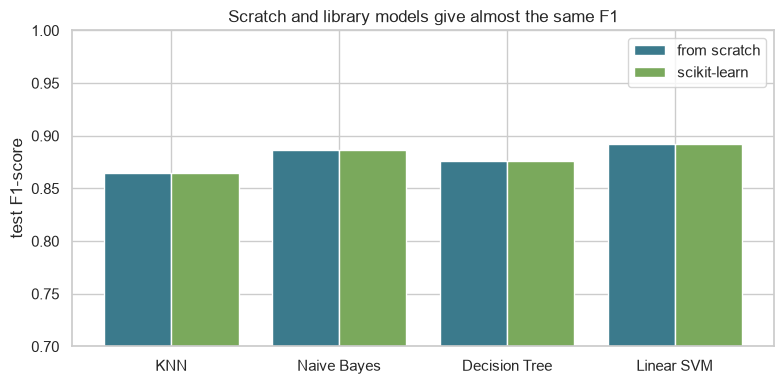

In [26]:
# same comparison in one picture
names = ["KNN", "Naive Bayes", "Decision Tree"]
scratch_f1 = [my_f1(y_test, scratch_results[n][0]) for n in names] + [my_f1(y_test, svm_pred_scratch)]
lib_f1 = [test_table.loc[n, "F1-score"] for n in names] + [my_f1(y_test, lib_linear_svm.predict(Xte))]
pos = np.arange(4)
plt.figure(figsize=(8, 4))
plt.bar(pos - 0.2, scratch_f1, 0.4, label="from scratch", color="#3b7a8c")
plt.bar(pos + 0.2, lib_f1, 0.4, label="scikit-learn", color="#7aa95c")
plt.xticks(pos, names + ["Linear SVM"]); plt.ylim(0.7, 1.0); plt.ylabel("test F1-score")
plt.title("Scratch and library models give almost the same F1"); plt.legend(); plt.tight_layout(); plt.show()

### What the comparison tells us

* Our KNN, Naive Bayes and Decision Tree gave the same label as the scikit-learn models on 100% of the test rows. So accuracy, precision, recall, F1 and ROC-AUC are exactly the same for each pair.
* Our Naive Bayes also matches scikit-learn in log loss (0.6452).
* The log loss of our KNN (0.7446) and Decision Tree (0.4821) is a little different from scikit-learn (0.7670 and 0.4902). The reason is not a mistake in the models. Both of them give probabilities of exactly 0 or 1 for many rows, and the log of 0 does not exist. So every library has to clip the probability to a tiny number first, and the size of that tiny number changes the penalty of each wrong answer. We clip at 0.000000000000001, scikit-learn uses a slightly smaller number. This tells us something real: the loss of KNN and trees depends a lot on this clipping because they are so sure about their answers.
* The scratch linear SVM reached F1 0.892 and the scikit-learn linear SVM reached 0.892. The weights are within 0.014 of each other, and the hinge loss is the same (0.2474 against 0.2478). The small difference is expected because we use gradient descent with random mini-batches, while the library solves the problem exactly.
* The RBF SVM from Part A is better (accuracy 0.907 against 0.893 for the linear one). The RBF kernel can draw a curved boundary, and the real boundary between good and not-good countries is not a straight line.

Writing the algorithms ourselves showed that none of the four is magic. KNN is a vote of the nearest rows, Naive Bayes is a product of bell curves, a Decision Tree is a list of yes or no questions, and a linear SVM is gradient descent on the hinge loss. The library is faster and has more options, but it does the same job.

# Part C: Regression with scikit-learn

## 15. The real-world use: predicting life expectancy

Governments and groups like the WHO want to know which health and money related steps help people live longer. If we can predict life expectancy from things like health spending, doctors, clean water and income, then:

* we can guess the life expectancy of places where fresh survey data is missing, and
* we can see which factors matter most, which helps in planning a budget.

This time we do not make classes. We predict the real number of years, so this is a regression problem. We use the same columns and the same country-wise split as before.

Life expectancy in the training rows: mean 66.9, spread 10.3, lowest 39.0, highest 83.3


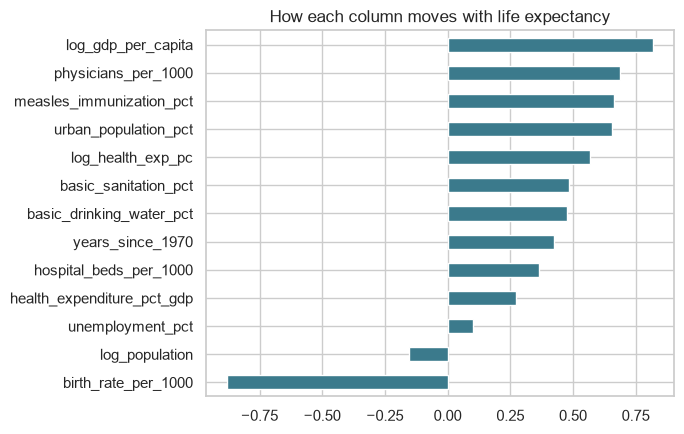

In [27]:
yr_train = train_df["life_expectancy"].values
yr_test  = test_df["life_expectancy"].values

print("Life expectancy in the training rows: mean %.1f, spread %.1f, lowest %.1f, highest %.1f" %
      (yr_train.mean(), yr_train.std(), yr_train.min(), yr_train.max()))

corr_target = train_df[FEATURES + ["life_expectancy"]].corr()["life_expectancy"].drop("life_expectancy").sort_values()
corr_target.plot(kind="barh", figsize=(7, 4.5), color="#3b7a8c")
plt.title("How each column moves with life expectancy"); plt.tight_layout(); plt.show()

## 16. Scores for regression

* MAE (mean absolute error): the average mistake in years. Easy to explain.
* MSE (mean squared error): the average of the squared mistakes. Big mistakes count more.
* RMSE: the square root of MSE, so it is in years again.
* R2 score: how much of the ups and downs in life expectancy the model explains. 1 is perfect and 0 is no better than always guessing the average.

In [28]:
def regression_scores(model, X, y):
    p = model.predict(X)
    mse = mean_squared_error(y, p)
    return {"MAE": mean_absolute_error(y, p), "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y, p)}

## 17. Training the regression models

We try six models, from simple to complex.
* Linear Regression: draws a straight line (or flat plane) through the data.
* Ridge Regression: linear regression with a penalty that keeps the weights small.
* Lasso Regression: linear regression with a penalty that can push useless weights to exactly zero.
* Decision Tree Regressor
* KNN Regressor
* Random Forest Regressor: many trees whose answers are averaged.

In [29]:
reg_grids = {
    "Linear Regression": (LinearRegression(), {}),
    "Ridge":  (Ridge(), {"reg__alpha": [0.01, 0.1, 1, 10, 100]}),
    "Lasso":  (Lasso(max_iter=20000), {"reg__alpha": [0.001, 0.01, 0.1, 0.5, 1]}),
    "Decision Tree": (DecisionTreeRegressor(random_state=RANDOM_STATE),
                      {"reg__max_depth": [4, 6, 8, 12, None], "reg__min_samples_leaf": [1, 5, 20]}),
    "KNN": (KNeighborsRegressor(), {"reg__n_neighbors": [3, 5, 9, 15], "reg__weights": ["uniform", "distance"]}),
    "Random Forest": (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
                      {"reg__n_estimators": [100, 200], "reg__max_depth": [8, 14, None], "reg__min_samples_leaf": [1, 3]}),
}

reg_models, reg_times, reg_params = {}, {}, {}
for name, (est, grid) in reg_grids.items():
    pipe = Pipeline([("scale", StandardScaler()), ("reg", est)])
    t0 = time.time()
    if grid:
        s = GridSearchCV(pipe, grid, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=1 if name == "Random Forest" else -1)
        s.fit(X_train, yr_train, groups=groups_train)
        reg_models[name] = s.best_estimator_
        reg_params[name] = s.best_params_
    else:
        reg_models[name] = pipe.fit(X_train, yr_train)
        reg_params[name] = "no settings to tune"
    reg_times[name] = time.time() - t0
    print(f"{name:18s} time = {reg_times[name]:5.1f}s | settings = {reg_params[name]}")

Linear Regression  time =   0.0s | settings = no settings to tune


Ridge              time =   0.0s | settings = {'reg__alpha': 100}
Lasso              time =   0.0s | settings = {'reg__alpha': 0.01}


Decision Tree      time =   0.3s | settings = {'reg__max_depth': 6, 'reg__min_samples_leaf': 20}


KNN                time =   0.2s | settings = {'reg__n_neighbors': 15, 'reg__weights': 'uniform'}


Random Forest      time =  28.1s | settings = {'reg__max_depth': None, 'reg__min_samples_leaf': 3, 'reg__n_estimators': 200}


## 18. Regression results

In [30]:
reg_test  = pd.DataFrame({n: regression_scores(m, X_test,  yr_test)  for n, m in reg_models.items()}).T
reg_train = pd.DataFrame({n: regression_scores(m, X_train, yr_train) for n, m in reg_models.items()}).T

print("Scores on the test rows")
show(reg_test)
print()
print("Scores on the training rows")
show(reg_train)

Scores on the test rows
Linear Regression:  MAE = 2.9942,  MSE = 17.0159,  RMSE = 4.1250,  R2 = 0.8383
Ridge:  MAE = 2.9726,  MSE = 16.9269,  RMSE = 4.1142,  R2 = 0.8391
Lasso:  MAE = 2.9845,  MSE = 16.9928,  RMSE = 4.1222,  R2 = 0.8385
Decision Tree:  MAE = 3.1533,  MSE = 18.7824,  RMSE = 4.3339,  R2 = 0.8215
KNN:  MAE = 3.0416,  MSE = 17.9149,  RMSE = 4.2326,  R2 = 0.8297
Random Forest:  MAE = 2.7410,  MSE = 14.3463,  RMSE = 3.7877,  R2 = 0.8637

Scores on the training rows
Linear Regression:  MAE = 3.1023,  MSE = 16.7448,  RMSE = 4.0920,  R2 = 0.8421
Ridge:  MAE = 3.1039,  MSE = 16.7619,  RMSE = 4.0941,  R2 = 0.8419
Lasso:  MAE = 3.1025,  MSE = 16.7505,  RMSE = 4.0927,  R2 = 0.8420
Decision Tree:  MAE = 2.4503,  MSE = 11.1489,  RMSE = 3.3390,  R2 = 0.8949
KNN:  MAE = 1.4126,  MSE = 4.6980,  RMSE = 2.1675,  R2 = 0.9557
Random Forest:  MAE = 0.4490,  MSE = 0.6801,  RMSE = 0.8247,  R2 = 0.9936


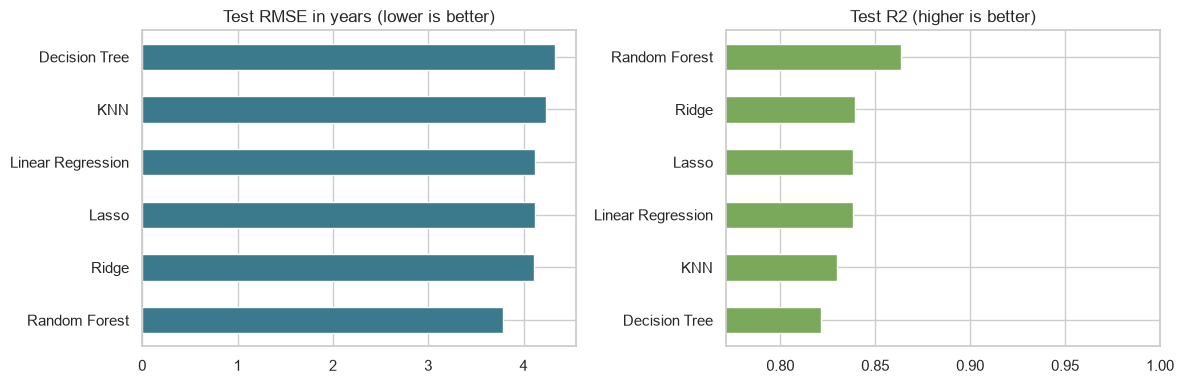

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
reg_test["RMSE"].sort_values().plot(kind="barh", ax=ax[0], color="#3b7a8c"); ax[0].set_title("Test RMSE in years (lower is better)")
reg_test["R2"].sort_values().plot(kind="barh", ax=ax[1], color="#7aa95c"); ax[1].set_title("Test R2 (higher is better)")
ax[1].set_xlim(reg_test["R2"].min() - 0.05, 1.0)
plt.tight_layout(); plt.show()

### 18.1 How close are the guesses? (best model)

Best regression model on the test rows: Random Forest


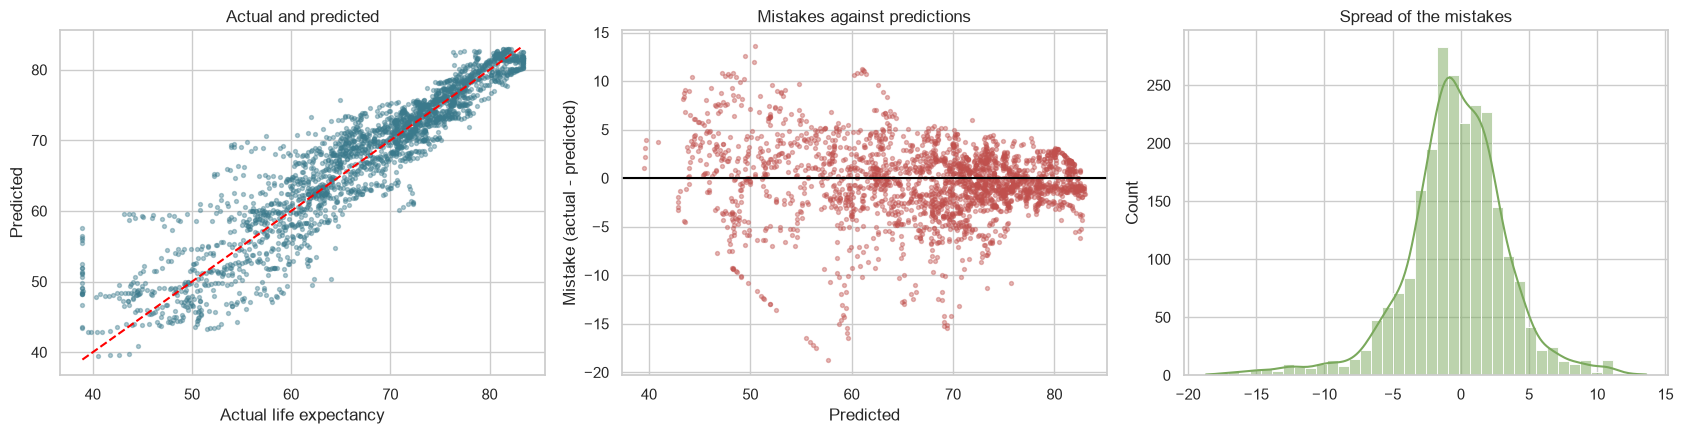

Guesses within 2 years of the real value: 50.0%
Guesses within 5 years of the real value: 86.0%


In [32]:
best_reg_name = reg_test["RMSE"].idxmin()
best_reg = reg_models[best_reg_name]
pred = best_reg.predict(X_test)
resid = yr_test - pred
print("Best regression model on the test rows:", best_reg_name)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(yr_test, pred, s=8, alpha=0.4, color="#3b7a8c")
lims = [yr_test.min(), yr_test.max()]
ax[0].plot(lims, lims, "r--"); ax[0].set_xlabel("Actual life expectancy"); ax[0].set_ylabel("Predicted"); ax[0].set_title("Actual and predicted")

ax[1].scatter(pred, resid, s=8, alpha=0.4, color="#c0504d"); ax[1].axhline(0, color="k")
ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Mistake (actual - predicted)"); ax[1].set_title("Mistakes against predictions")

sns.histplot(resid, bins=40, kde=True, ax=ax[2], color="#7aa95c"); ax[2].set_title("Spread of the mistakes")
plt.tight_layout(); plt.show()

print("Guesses within 2 years of the real value: %.1f%%" % (np.mean(np.abs(resid) <= 2) * 100))
print("Guesses within 5 years of the real value: %.1f%%" % (np.mean(np.abs(resid) <= 5) * 100))

### 18.2 Which columns matter the most?

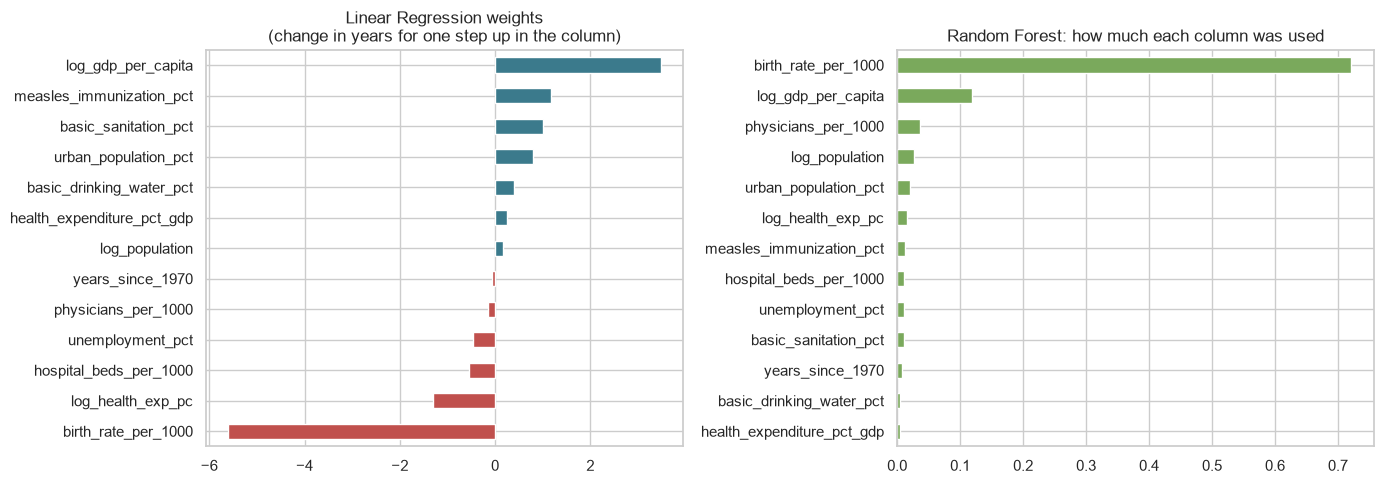

In [33]:
lin = reg_models["Linear Regression"].named_steps["reg"]
coef = pd.Series(lin.coef_, index=FEATURES).sort_values()
rf = reg_models["Random Forest"].named_steps["reg"]
rf_imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
coef.plot(kind="barh", ax=ax[0], color=["#c0504d" if v < 0 else "#3b7a8c" for v in coef])
ax[0].set_title("Linear Regression weights\n(change in years for one step up in the column)")
rf_imp.plot(kind="barh", ax=ax[1], color="#7aa95c"); ax[1].set_title("Random Forest: how much each column was used")
plt.tight_layout(); plt.show()

### 18.3 Where are the biggest mistakes?

In [34]:
err = test_df[["country", "income_group", "year", "life_expectancy"]].copy()
err["predicted"] = pred
err["abs_error"] = np.abs(resid)

print("Average mistake in years for each income group:")
for grp, val in err.groupby("income_group").abs_error.mean().sort_values().items():
    print(f"   {grp}: {val:.2f}")

print()
print("The five biggest mistakes:")
for _, r in err.sort_values("abs_error", ascending=False).head(5).iterrows():
    print(f"   {r['country']} ({r['income_group']}), {int(r['year'])}: actual {r['life_expectancy']:.2f}, predicted {r['predicted']:.2f}")

Average mistake in years for each income group:
   High income: 1.71
   Low income: 3.27
   Upper middle income: 3.60
   Lower middle income: 3.78

The five biggest mistakes:
   Timor-Leste (Lower middle income), 1980: actual 38.95, predicted 57.64
   Timor-Leste (Lower middle income), 1984: actual 38.95, predicted 56.47
   Timor-Leste (Lower middle income), 1983: actual 38.95, predicted 56.18
   Timor-Leste (Lower middle income), 1982: actual 38.95, predicted 55.88
   Timor-Leste (Lower middle income), 1981: actual 38.95, predicted 55.46


### What the regression results tell us

Test scores as MAE and RMSE in years, and R2:

* Linear Regression: 2.99 and 4.13, R2 0.838
* Ridge: 2.97 and 4.11, R2 0.839
* Lasso: 2.98 and 4.12, R2 0.839
* Decision Tree: 3.15 and 4.33, R2 0.821
* KNN: 3.04 and 4.23, R2 0.830
* Random Forest: 2.74 and 3.79, R2 0.864

All the models explain about 82% to 86% of the ups and downs in life expectancy using only health, money and population columns. That is a good result for such a big topic.

Random Forest is the best on the test rows (RMSE 3.8 years, R2 0.864), but it is only about 0.3 years better than plain Linear Regression. On the training rows the forest reaches an R2 of 0.99, so it clearly remembers part of the training data. A simple line already catches most of the pattern.

Ridge and Lasso give almost the same result as Linear Regression. This shows that the simple linear model was not overfitting much, so the penalty had little to fix.

Which columns matter? Birth rate is by far the strongest. Its link with life expectancy is -0.88, and the Random Forest gives it about 72% of its total use. GDP per capita comes next. This does not mean a high birth rate causes a short life. Both come from the same background, like poverty and weak health care. The model finds a pattern, not a cause.

Look at one odd thing: in the linear model, log_health_exp_pc has a negative weight, although on its own it moves up with life expectancy (link of 0.57). This happens because it moves together with GDP per capita, and the model shares the credit between the two. So the weights of linked columns should not be read one by one.

Where does it go wrong? The mistake is smallest for high income countries (about 1.7 years) and bigger (3.3 to 3.8 years) for the other groups. The five biggest mistakes are all for Timor-Leste in the early 1980s, where the data says 38.95 years. That same number repeats for many years in a row, which looks like a floor value that came from our cleaning in the first assignment. It is probably not a real life expectancy, and we should keep this in mind.

In practice, about half of the guesses are within 2 years of the real value and 86% are within 5 years.

# Part D: Regression models written from scratch

Here we write four of the regression models ourselves and compare them with the scikit-learn ones from Part C. We use the same scaled data and the same settings that were picked by the grid search.
* Linear Regression with the normal equation
* Ridge Regression with its closed form
* KNN Regressor
* Decision Tree Regressor (we reuse the tree from Part B, which already supports regression)

Lasso and Random Forest are left to the library, since Lasso has no simple closed form and the forest is just many trees.

## 19. Regression scores by hand

In [35]:
def my_mae(y, p):
    return np.mean(np.abs(y - p))

def my_mse(y, p):
    return np.mean((y - p) ** 2)

def my_rmse(y, p):
    return np.sqrt(my_mse(y, p))

def my_r2(y, p):
    ss_res = np.sum((y - p) ** 2)                 # what the model could not explain
    ss_tot = np.sum((y - y.mean()) ** 2)          # total ups and downs
    return 1 - ss_res / ss_tot

def my_regression_scores(y, p):
    return {"MAE": my_mae(y, p), "MSE": my_mse(y, p), "RMSE": my_rmse(y, p), "R2": my_r2(y, p)}

p_check = reg_models["Linear Regression"].predict(X_test)
print("Ours         :", {k: round(v, 6) for k, v in my_regression_scores(yr_test, p_check).items()})
print("scikit-learn :", {k: round(v, 6) for k, v in regression_scores(reg_models["Linear Regression"], X_test, yr_test).items()})

Ours         : {'MAE': np.float64(2.994219), 'MSE': np.float64(17.015936), 'RMSE': np.float64(4.125038), 'R2': np.float64(0.838283)}
scikit-learn : {'MAE': 2.994219, 'MSE': 17.015936, 'RMSE': np.float64(4.125038), 'R2': 0.838283}


## 20. Linear and Ridge regression with a formula

Linear regression has an exact answer called the normal equation. We put the column means to zero, and then

w = (X^T X + alpha x I)^-1 X^T y

and the bias is b = (mean of y) - (mean of x) . w

For plain linear regression alpha is 0. For Ridge, alpha is above 0, which pulls the weights toward zero. The bias is never penalised.

In [36]:
def normal_equation(X, y, alpha=0.0):
    x_mean, y_mean = X.mean(axis=0), y.mean()
    Xc, yc = X - x_mean, y - y_mean
    w = np.linalg.solve(Xc.T @ Xc + alpha * np.eye(X.shape[1]), Xc.T @ yc)
    b = y_mean - x_mean @ w
    return w, b

w_lin, b_lin = normal_equation(Xtr, yr_train)
alpha_ridge = reg_params["Ridge"]["reg__alpha"]
w_rdg, b_rdg = normal_equation(Xtr, yr_train, alpha=alpha_ridge)
print("Ridge alpha chosen by the grid search:", alpha_ridge)

Ridge alpha chosen by the grid search: 100


## 21. KNN regressor and Decision Tree regressor

In [37]:
k_reg = reg_params["KNN"]["reg__n_neighbors"]
print("KNN regressor: library picked k =", k_reg, "and weights =", reg_params["KNN"]["reg__weights"])
my_knn_reg = MyKNN(k=k_reg, task="regression").fit(Xtr, yr_train)       # simple average of the neighbours
knn_reg_pred = my_knn_reg.predict(Xte)

d_reg = reg_params["Decision Tree"]["reg__max_depth"]
l_reg = reg_params["Decision Tree"]["reg__min_samples_leaf"]
print("Tree regressor: library picked max_depth =", d_reg, "and min_samples_leaf =", l_reg)
my_tree_reg = MyDecisionTree("regression", d_reg, l_reg).fit(Xtr, yr_train)
tree_reg_pred = my_tree_reg.predict(Xte)

KNN regressor: library picked k = 15 and weights = uniform
Tree regressor: library picked max_depth = 6 and min_samples_leaf = 20


## 22. Scratch regressors against the scikit-learn regressors

In [38]:
scratch_reg_pred = {
    "Linear Regression": Xte @ w_lin + b_lin,
    "Ridge":             Xte @ w_rdg + b_rdg,
    "KNN":               knn_reg_pred,
    "Decision Tree":     tree_reg_pred,
}
for name, p in scratch_reg_pred.items():
    mine = my_regression_scores(yr_test, p)
    lib = reg_test.loc[name]
    print(name)
    print("   scratch      :", ", ".join(f"{k} {v:.4f}" for k, v in mine.items()))
    print("   scikit-learn :", ", ".join(f"{k} {lib[k]:.4f}" for k in mine))

print()
lib_w = reg_models["Linear Regression"].named_steps["reg"].coef_
print("Largest difference between scratch and library weights (Linear):", np.abs(w_lin - lib_w).max())
print("Largest difference between scratch and library weights (Ridge) :", np.abs(w_rdg - reg_models["Ridge"].named_steps["reg"].coef_).max())

Linear Regression
   scratch      : MAE 2.9942, MSE 17.0159, RMSE 4.1250, R2 0.8383
   scikit-learn : MAE 2.9942, MSE 17.0159, RMSE 4.1250, R2 0.8383
Ridge
   scratch      : MAE 2.9726, MSE 16.9269, RMSE 4.1142, R2 0.8391
   scikit-learn : MAE 2.9726, MSE 16.9269, RMSE 4.1142, R2 0.8391
KNN
   scratch      : MAE 3.0416, MSE 17.9149, RMSE 4.2326, R2 0.8297
   scikit-learn : MAE 3.0416, MSE 17.9149, RMSE 4.2326, R2 0.8297
Decision Tree
   scratch      : MAE 3.1533, MSE 18.7824, RMSE 4.3339, R2 0.8215
   scikit-learn : MAE 3.1533, MSE 18.7824, RMSE 4.3339, R2 0.8215

Largest difference between scratch and library weights (Linear): 1.8207657603852567e-13
Largest difference between scratch and library weights (Ridge) : 3.066991105526995e-15


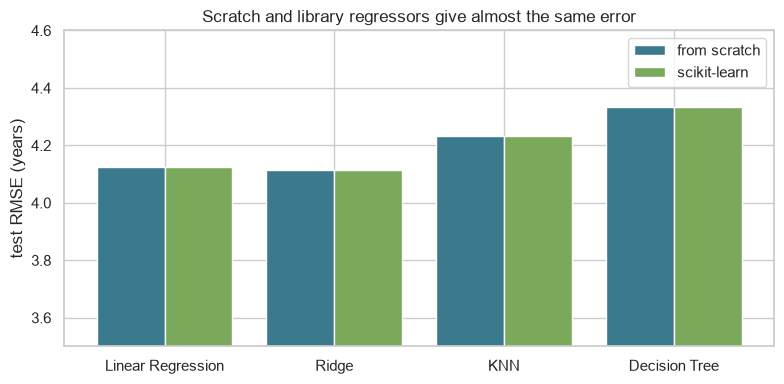

In [39]:
names = list(scratch_reg_pred)
scratch_rmse = [my_rmse(yr_test, scratch_reg_pred[n]) for n in names]
lib_rmse = [reg_test.loc[n, "RMSE"] for n in names]
pos = np.arange(len(names))
plt.figure(figsize=(8, 4))
plt.bar(pos - 0.2, scratch_rmse, 0.4, label="from scratch", color="#3b7a8c")
plt.bar(pos + 0.2, lib_rmse, 0.4, label="scikit-learn", color="#7aa95c")
plt.xticks(pos, names); plt.ylabel("test RMSE (years)"); plt.ylim(3.5, 4.6)
plt.title("Scratch and library regressors give almost the same error"); plt.legend(); plt.tight_layout(); plt.show()

### What the comparison tells us

* Linear Regression and Ridge written from the formula give the same scores as scikit-learn to four decimal places (RMSE 4.1250 and 4.1142). The weights differ only after the twelfth decimal place, which is just computer rounding.
* Our KNN regressor and our tree regressor give exactly the same scores as scikit-learn (RMSE 4.2326 and 4.3339).
* The same tree code worked for both jobs. For classification it measures how mixed a group is with Gini, and for regression it measures the variance of the target. Everything else is the same.

So for linear models the exact formula is enough. It is quick and it needs no learning rate. The next part shows the other way to get the same weights, which is gradient descent.

# Part E: Gradient Descent for Linear Regression

## 23. The idea

Linear regression guesses with a line (or flat plane):

$$\hat{y} = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b$$

To find good values of the weights w and the bias b, we need a number that tells how wrong the line is. We use the mean squared error as the cost:

$$J(w, b) = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}_i - y_i)^2$$

Gradient descent finds the lowest point of this cost in small steps. We start with all weights at zero. In each step we find the slope of the cost and move the weights a little bit in the opposite direction:

$$w \leftarrow w - \alpha \, \frac{\partial J}{\partial w} \qquad b \leftarrow b - \alpha \, \frac{\partial J}{\partial b}$$

with

$$\frac{\partial J}{\partial w} = \frac{2}{m} X^T(\hat{y} - y) \qquad \frac{\partial J}{\partial b} = \frac{2}{m} \sum (\hat{y}_i - y_i)$$

Here alpha is the learning rate, which is the size of each step.

In this part we will
1. write batch, stochastic and mini-batch gradient descent ourselves with NumPy,
2. check that they reach the same answer as the exact formula and as scikit-learn,
3. see what happens for different learning rates, batch sizes and with or without scaling.

## 24. Gradient descent from scratch

One function does all three kinds. The only difference is how many rows are used to work out each slope.

* Batch gradient descent uses all rows for every step.
* Stochastic gradient descent (SGD) uses one random row for every step.
* Mini-batch gradient descent uses a small group of rows, for example 32.

After every epoch (one full pass over the data) we save the cost, so that we can draw the learning curve later.

In [40]:
ytr, yte = yr_train, yr_test

def mse_cost(X, y, w, b):
    err = X @ w + b - y
    return np.mean(err ** 2)

def gradient_descent(X, y, lr=0.1, epochs=100, batch_size=None, seed=0, X_val=None, y_val=None):
    # batch_size None means all rows, 1 means stochastic, any other number means mini-batch
    rng = np.random.default_rng(seed)
    m, n = X.shape
    w, b = np.zeros(n), 0.0
    bs = m if batch_size is None else batch_size

    history = {"cost": [mse_cost(X, y, w, b)], "val_cost": [], "w": [w.copy()], "b": [b]}
    if X_val is not None:
        history["val_cost"].append(mse_cost(X_val, y_val, w, b))

    for epoch in range(epochs):
        order = rng.permutation(m) if bs < m else np.arange(m)
        for start in range(0, m, bs):
            idx = order[start:start + bs]
            Xb, yb = X[idx], y[idx]
            error = Xb @ w + b - yb
            grad_w = 2 * Xb.T @ error / len(idx)
            grad_b = 2 * error.mean()
            w = w - lr * grad_w
            b = b - lr * grad_b
            if not np.all(np.isfinite(w)):              # the learning rate was too big, so stop
                history["cost"].append(np.inf)
                return w, b, history
        history["cost"].append(mse_cost(X, y, w, b))
        history["w"].append(w.copy()); history["b"].append(b)
        if X_val is not None:
            history["val_cost"].append(mse_cost(X_val, y_val, w, b))
    return w, b, history

## 25. First check: does it reach the right answer?

We compare our gradient descent with the normal equation from Part D and with scikit-learn's LinearRegression. If our code is right, the weights should be almost the same.

In [41]:
w_exact, b_exact = normal_equation(Xtr, ytr)
sk = LinearRegression().fit(Xtr, ytr)
w_gd, b_gd, hist_gd = gradient_descent(Xtr, ytr, lr=0.1, epochs=300)

for i, name in enumerate(FEATURES):
    print(f"{name}:  normal equation {w_exact[i]:.4f},  scikit-learn {sk.coef_[i]:.4f},  our gradient descent {w_gd[i]:.4f}")
print(f"bias:  normal equation {b_exact:.4f},  scikit-learn {sk.intercept_:.4f},  our gradient descent {b_gd:.4f}")

print()
print("Largest weight difference between gradient descent and the exact answer:", np.abs(w_gd - w_exact).max().round(6))
print("Final training MSE:  exact %.4f,  gradient descent %.4f" % (mse_cost(Xtr, ytr, w_exact, b_exact), hist_gd["cost"][-1]))

health_expenditure_pct_gdp:  normal equation 0.2493,  scikit-learn 0.2493,  our gradient descent 0.2451
log_health_exp_pc:  normal equation -1.2944,  scikit-learn -1.2944,  our gradient descent -1.2777
physicians_per_1000:  normal equation -0.1479,  scikit-learn -0.1479,  our gradient descent -0.1497
hospital_beds_per_1000:  normal equation -0.5575,  scikit-learn -0.5575,  our gradient descent -0.5566
basic_sanitation_pct:  normal equation 0.9995,  scikit-learn 0.9995,  our gradient descent 0.9899
basic_drinking_water_pct:  normal equation 0.3951,  scikit-learn 0.3951,  our gradient descent 0.3957
measles_immunization_pct:  normal equation 1.1673,  scikit-learn 1.1673,  our gradient descent 1.1708
log_gdp_per_capita:  normal equation 3.4908,  scikit-learn 3.4908,  our gradient descent 3.4773
unemployment_pct:  normal equation -0.4720,  scikit-learn -0.4720,  our gradient descent -0.4715
urban_population_pct:  normal equation 0.7902,  scikit-learn 0.7902,  our gradient descent 0.7924
lo

The numbers match up to a few decimal places, so our code works.

## 26. The learning curve

We draw the training cost after each epoch. A good curve drops fast at the start and then goes flat. The flat part means the algorithm has converged, which means it has reached the bottom.

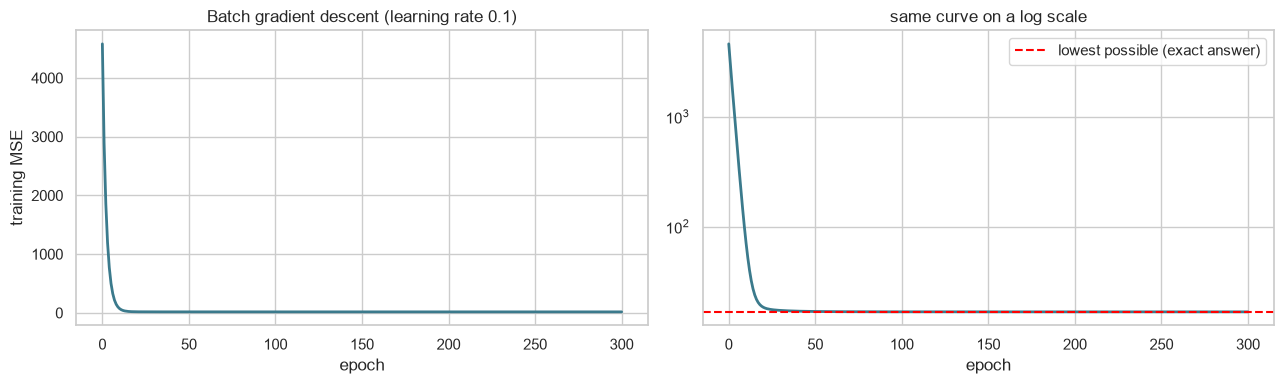

Cost at epoch 0: 4579.16
Cost at epoch 10: 70.81
Cost at epoch 50: 16.88
Cost at epoch 300: 16.74


In [42]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist_gd["cost"], color="#3b7a8c", lw=2)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training MSE"); ax[0].set_title("Batch gradient descent (learning rate 0.1)")
ax[1].plot(hist_gd["cost"], color="#3b7a8c", lw=2)
ax[1].axhline(mse_cost(Xtr, ytr, w_exact, b_exact), color="red", ls="--", label="lowest possible (exact answer)")
ax[1].set_yscale("log"); ax[1].set_xlabel("epoch"); ax[1].set_title("same curve on a log scale"); ax[1].legend()
plt.tight_layout(); plt.show()

for e in [0, 10, 50, 300]:
    print(f"Cost at epoch {e}: {hist_gd['cost'][e]:.2f}")

## 27. Watching gradient descent move (one column)

With many columns we cannot draw the cost. So for this picture we use only one column, log_gdp_per_capita. The cost is then a bowl shape over two numbers, the weight and the bias. The red line shows the route taken by gradient descent. The second picture shows how the fitted line gets better as training goes on.

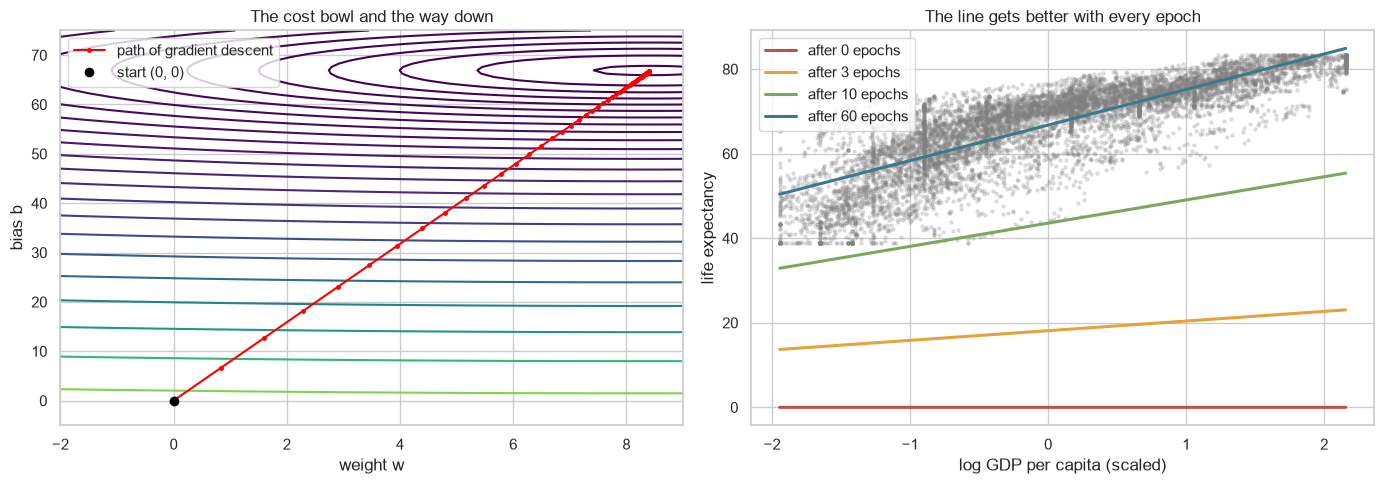

In [43]:
j = FEATURES.index("log_gdp_per_capita")
x1 = Xtr[:, [j]]

w1, b1, h1 = gradient_descent(x1, ytr, lr=0.05, epochs=60)
path_w = np.array([w[0] for w in h1["w"]]); path_b = np.array(h1["b"])

ws = np.linspace(-2, 9, 120); bs_ = np.linspace(-5, 75, 120)
W, B = np.meshgrid(ws, bs_)
Z = np.array([[mse_cost(x1, ytr, np.array([wv]), bv) for wv in ws] for bv in bs_])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].contour(W, B, Z, levels=np.geomspace(Z.min() + 1, Z.max(), 25), cmap="viridis")
ax[0].plot(path_w, path_b, "r.-", lw=1.5, ms=5, label="path of gradient descent")
ax[0].plot(path_w[0], path_b[0], "ko", label="start (0, 0)")
ax[0].set_xlabel("weight w"); ax[0].set_ylabel("bias b"); ax[0].set_title("The cost bowl and the way down"); ax[0].legend()

order = np.argsort(x1[:, 0])
ax[1].scatter(x1[:, 0], ytr, s=5, alpha=0.2, color="grey")
for ep, col in [(0, "#c0504d"), (3, "#e6a23c"), (10, "#7aa95c"), (60, "#3b7a8c")]:
    ax[1].plot(x1[order, 0], x1[order, 0] * h1["w"][ep][0] + h1["b"][ep], color=col, lw=2.2, label=f"after {ep} epochs")
ax[1].set_xlabel("log GDP per capita (scaled)"); ax[1].set_ylabel("life expectancy"); ax[1].set_title("The line gets better with every epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

## 28. What the learning rate does

The learning rate is the most important setting. We try five values. A very small one makes learning slow. A good one comes down smoothly. A very large one jumps over the bottom, and the cost can even blow up.

learning rate 0.001: final cost 3033, still coming down
learning rate 0.01: final cost 97.98, still coming down
learning rate 0.1: final cost 16.76, reached the bottom, within 1% of the best after 47 epochs
learning rate 0.9: final cost 1.31e+192, blew up
learning rate 1.05: final cost 7.652e+206, blew up


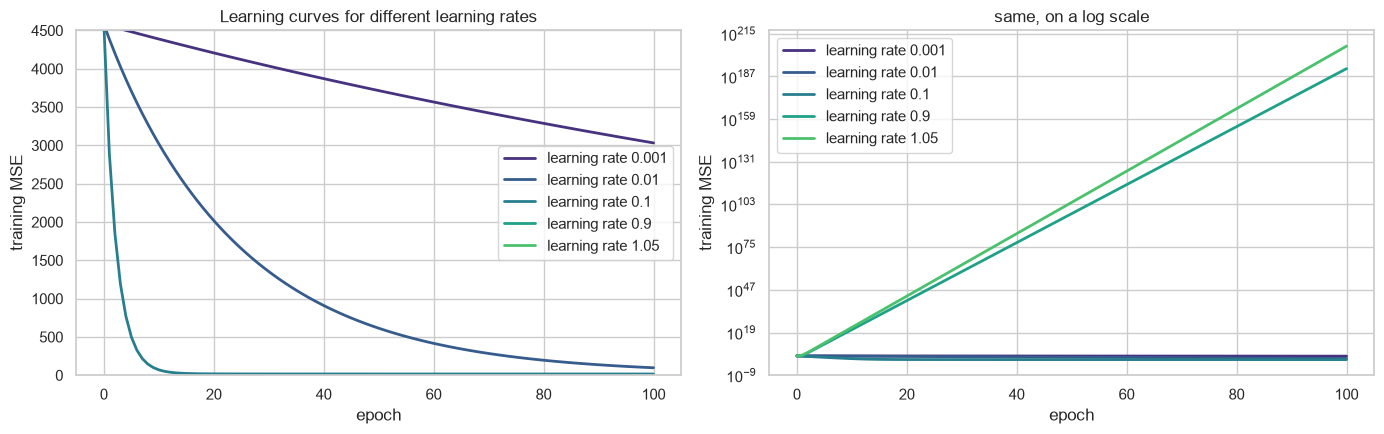

In [44]:
lrs = [0.001, 0.01, 0.1, 0.9, 1.05]
best_possible = mse_cost(Xtr, ytr, w_exact, b_exact)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for lr in lrs:
    w, b, h = gradient_descent(Xtr, ytr, lr=lr, epochs=100)
    c = np.array(h["cost"])
    ax[0].plot(c, lw=2, label=f"learning rate {lr}")
    ax[1].plot(c, lw=2, label=f"learning rate {lr}")
    close = np.where(c <= best_possible * 1.01)[0]
    status = "blew up" if (not np.isfinite(c[-1]) or c[-1] > c[0]) else ("reached the bottom" if len(close) else "still coming down")
    when = f", within 1% of the best after {close[0]} epochs" if len(close) else ""
    print(f"learning rate {lr}: final cost {c[-1]:.4g}, {status}{when}")
ax[0].set_ylim(0, 4500); ax[0].set_title("Learning curves for different learning rates")
ax[1].set_yscale("log"); ax[1].set_title("same, on a log scale")
for a in ax: a.set_xlabel("epoch"); a.set_ylabel("training MSE"); a.legend()
plt.tight_layout(); plt.show()

What we see:

* A learning rate of 0.001 is far too small. After 100 epochs the cost is still above 3000, so it has barely started.
* A learning rate of 0.01 is also slow. At epoch 100 it is still coming down (cost about 98).
* A learning rate of 0.1 is good. The cost falls very fast (from 4579 to about 71 in 10 epochs) and it gets within 1% of the best value after 47 epochs.
* Learning rates of 0.9 and 1.05 are too big. Every step jumps over the bottom of the bowl and lands higher on the other side, so the cost grows at every step and finally becomes a number with more than 190 digits. This is called divergence.

So there is a sweet spot. A rate that is too small wastes time and a rate that is too big breaks the algorithm. For this problem the safe limit lies somewhere between 0.1 and 0.9.

## 29. Batch, stochastic and mini-batch

Now we compare the three kinds. Stochastic and mini-batch change the weights many times in one epoch, so we give them a smaller learning rate to keep the noise down.

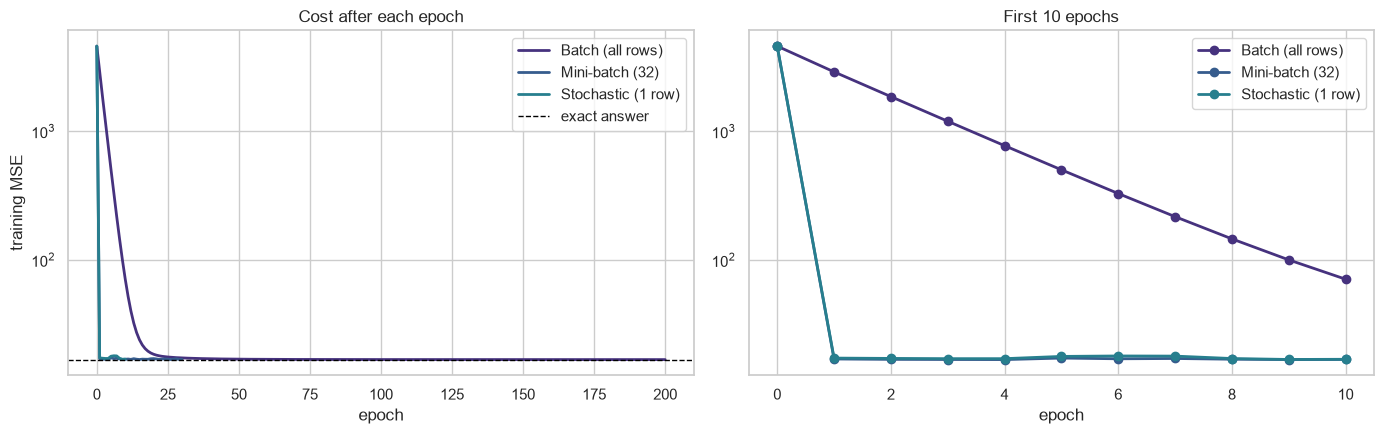

Batch (all rows): 200 epochs, 200 weight updates, train MSE 16.7456, test MSE 17.0427, time 0.03 s, biggest weight error 0.0712
Mini-batch (32): 30 epochs, 8910 weight updates, train MSE 16.7951, test MSE 17.2351, time 0.05 s, biggest weight error 0.0725
Stochastic (1 row): 10 epochs, 94950 weight updates, train MSE 16.8988, test MSE 17.2016, time 0.48 s, biggest weight error 0.1845


In [45]:
configs = {
    "Batch (all rows)":   dict(lr=0.1,   batch_size=None, epochs=200),
    "Mini-batch (32)":    dict(lr=0.02,  batch_size=32,   epochs=30),
    "Stochastic (1 row)": dict(lr=0.002, batch_size=1,    epochs=10),
}
runs = {}
for name, cfg in configs.items():
    t0 = time.time()
    w, b, h = gradient_descent(Xtr, ytr, X_val=Xte, y_val=yte, **cfg)
    runs[name] = dict(w=w, b=b, h=h, time=time.time() - t0, cfg=cfg)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name, r in runs.items():
    ax[0].plot(r["h"]["cost"], lw=2, label=name)
    ax[1].plot(r["h"]["cost"][:11], "o-", lw=2, label=name)
ax[0].axhline(best_possible, color="k", ls="--", lw=1, label="exact answer")
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training MSE"); ax[0].set_title("Cost after each epoch"); ax[0].legend()
ax[1].set_yscale("log"); ax[1].set_xlabel("epoch"); ax[1].set_title("First 10 epochs"); ax[1].legend()
plt.tight_layout(); plt.show()

for name, r in runs.items():
    bsz = r["cfg"]["batch_size"]
    updates = r["cfg"]["epochs"] * (1 if bsz is None else int(np.ceil(len(Xtr) / bsz)))
    print(f"{name}: {r['cfg']['epochs']} epochs, {updates} weight updates, train MSE {r['h']['cost'][-1]:.4f}, "
          f"test MSE {r['h']['val_cost'][-1]:.4f}, time {r['time']:.2f} s, biggest weight error {np.abs(r['w'] - w_exact).max():.4f}")

What we see:

* All three kinds end up at almost the same place. Their final training MSE (16.75 to 16.90) is very near the lowest possible value (16.74), and their test MSE (17.0 to 17.2) is also close.
* Batch gradient descent has the smoothest curve and the most accurate weights (the biggest weight error is 0.07). Every step is exact, but every step uses all the rows. Here it is still fast (0.03 seconds) because our data is small. On a very large dataset one step would be slow.
* Stochastic gradient descent changes the weights after every single row, which is 94,950 updates in only 10 epochs. Its path is noisy, and it keeps shaking around the minimum instead of settling. Its weight error is the largest (0.18), and it was the slowest in our run because Python has to loop over one row at a time.
* Mini-batch is in the middle. It is quicker per epoch than stochastic and less noisy. It is the usual choice for big problems, such as deep learning, because it also suits GPUs well.

In short, batch is smooth but costly for each step, stochastic is cheap for each step but noisy, and mini-batch gives a good balance of both.

## 30. Why scaling matters for gradient descent

In the first assignment we scaled the columns. This is the reason. If one column is in millions and another is between 0 and 1, the cost becomes a long narrow valley. Gradient descent then zig-zags and needs a tiny learning rate. We train on the unscaled data and compare it with the scaled data.

Range of the columns before scaling:
   log_gdp_per_capita: 4.78 to 11.41
   physicians_per_1000: 0.02 to 5.17
   basic_sanitation_pct: 8.70 to 100.00
   years_since_1970: 0.00 to 54.00
Lowest possible cost with these 4 columns: 30.12

scaled, learning rate 0.1: cost after 300 epochs = 30.12
unscaled, learning rate 0.1: cost after 300 epochs = inf
unscaled, learning rate 0.0001: cost after 300 epochs = 128.5
unscaled, learning rate 0.00001: cost after 300 epochs = 149.5


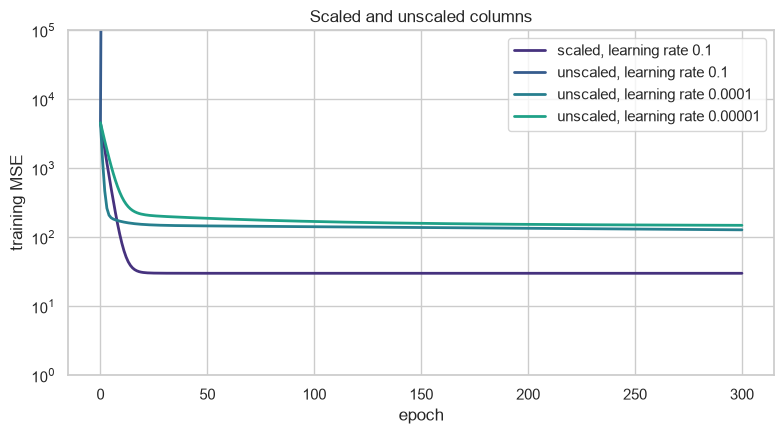

In [46]:
cols = ["log_gdp_per_capita", "physicians_per_1000", "basic_sanitation_pct", "years_since_1970"]
ci = [FEATURES.index(c) for c in cols]
Xraw = X_train[:, ci]
Xsc  = Xtr[:, ci]
print("Range of the columns before scaling:")
for c, lo, hi in zip(cols, Xraw.min(axis=0), Xraw.max(axis=0)):
    print(f"   {c}: {lo:.2f} to {hi:.2f}")

Xb4 = np.c_[np.ones(len(Xsc)), Xsc]
th4 = np.linalg.solve(Xb4.T @ Xb4, Xb4.T @ ytr)
print("Lowest possible cost with these 4 columns: %.2f" % mse_cost(Xsc, ytr, th4[1:], th4[0]))
print()

tests = {"scaled, learning rate 0.1": (Xsc, 0.1), "unscaled, learning rate 0.1": (Xraw, 0.1),
         "unscaled, learning rate 0.0001": (Xraw, 0.0001), "unscaled, learning rate 0.00001": (Xraw, 0.00001)}
plt.figure(figsize=(8, 4.5))
for name, (Xin, lr) in tests.items():
    _, _, h = gradient_descent(Xin, ytr, lr=lr, epochs=300)
    c = np.array(h["cost"]); c = np.where(np.isfinite(c), c, np.nan)
    plt.plot(c, lw=2, label=name)
    print(f"{name}: cost after 300 epochs = {h['cost'][-1]:.4g}")
plt.yscale("log"); plt.ylim(top=1e5); plt.xlabel("epoch"); plt.ylabel("training MSE")
plt.title("Scaled and unscaled columns"); plt.legend(); plt.tight_layout(); plt.show()

What we see:

* On the scaled columns a learning rate of 0.1 works well, and after 300 epochs the cost (30.12) is the same as the exact answer for these four columns.
* On the unscaled columns the same learning rate of 0.1 blows up, because columns like basic_sanitation_pct (up to 100) and years_since_1970 (up to 54) give very large slopes.
* The only way to keep the unscaled data stable is a much smaller learning rate (0.0001 or 0.00001). But then learning is so slow that after 300 epochs the cost is still 128 and 149, far from the best value of 30.

This is why we scale the columns. It lets us use one comfortable learning rate for all the weights and reach the bottom much faster.

## 31. Gradient descent in a library

scikit-learn has its own gradient descent version for linear models, called SGDRegressor. We set it up with no penalty and a fixed learning rate, which is the same kind of training that we wrote by hand, and we see how it compares on the test rows.

In [47]:
sgd_lib = SGDRegressor(penalty=None, learning_rate="constant", eta0=0.01, max_iter=50, tol=None, random_state=RANDOM_STATE).fit(Xtr, ytr)

def weight_scores(w, b, X, y):
    return my_regression_scores(y, X @ w + b)

final = {
    "Our batch gradient descent":      weight_scores(runs["Batch (all rows)"]["w"], runs["Batch (all rows)"]["b"], Xte, yte),
    "Our mini-batch gradient descent": weight_scores(runs["Mini-batch (32)"]["w"], runs["Mini-batch (32)"]["b"], Xte, yte),
    "Our stochastic gradient descent": weight_scores(runs["Stochastic (1 row)"]["w"], runs["Stochastic (1 row)"]["b"], Xte, yte),
    "scikit-learn SGDRegressor":       weight_scores(sgd_lib.coef_, sgd_lib.intercept_[0], Xte, yte),
    "Normal equation (ours)":          weight_scores(w_exact, b_exact, Xte, yte),
    "scikit-learn LinearRegression":   weight_scores(sk.coef_, sk.intercept_, Xte, yte),
}
print("Scores on the test rows")
show(pd.DataFrame(final).T)
print()
print("Largest weight difference between SGDRegressor and the exact answer:", np.abs(sgd_lib.coef_ - w_exact).max().round(4))

Scores on the test rows
Our batch gradient descent:  MAE = 2.9941,  MSE = 17.0427,  RMSE = 4.1283,  R2 = 0.8380
Our mini-batch gradient descent:  MAE = 3.0231,  MSE = 17.2351,  RMSE = 4.1515,  R2 = 0.8362
Our stochastic gradient descent:  MAE = 2.9939,  MSE = 17.2016,  RMSE = 4.1475,  R2 = 0.8365
scikit-learn SGDRegressor:  MAE = 2.9522,  MSE = 16.7418,  RMSE = 4.0917,  R2 = 0.8409
Normal equation (ours):  MAE = 2.9942,  MSE = 17.0159,  RMSE = 4.1250,  R2 = 0.8383
scikit-learn LinearRegression:  MAE = 2.9942,  MSE = 17.0159,  RMSE = 4.1250,  R2 = 0.8383

Largest weight difference between SGDRegressor and the exact answer: 0.3797


### Conclusion of Part E

* Our NumPy gradient descent reaches almost the same weights and test scores as the exact formula and scikit-learn (R2 between 0.836 and 0.838, against 0.838). The tiny difference is there because we stop after a fixed number of epochs.
* The scikit-learn SGDRegressor gave a similar result (R2 0.841). Its weights are up to 0.38 away from the exact ones because, like our stochastic version, it keeps moving around the minimum. That small noise happened to help a little on the test rows, but it is not a real gain.
* The learning rate decides everything: 0.1 works, 0.001 and 0.01 are too slow, and 0.9 and above blow up.
* Batch is smooth, stochastic is noisy and mini-batch is a practical middle way.
* Scaling is a must for gradient descent. Without it we need a tiny learning rate and training is very slow, or it blows up.
* For a small linear problem like this one the exact formula is the quickest way. Gradient descent becomes useful when the data is too big for the formula or when the model has no exact formula at all, like logistic regression and neural networks.

# Part F: Final summary

## 32. How suitable is each algorithm for different classification tasks

SVM
* Good at: the best accuracy, F1 and loss here. It handles many linked numeric columns and overfits very little.
* Not good at: it is the slowest to train and gets slower quickly as rows increase. It needs scaling, is hard to explain, and its probabilities need extra work.
* Use it when: the data is small or medium, the columns are numbers, and accuracy matters more than speed or a simple explanation.

Decision Tree
* Good at: it is very easy to explain with if-then rules. It needs no scaling, it is fast, and it shows which columns matter.
* Not good at: it overfits when it is deep. Its probabilities are rough, so the loss is high. A small change in data can change the whole tree.
* Use it when: the decision must be explained to people, for example a health department, or the data has mixed kinds of columns.

KNN
* Good at: there is no training step, the idea is simple, and it works well for local patterns.
* Not good at: prediction is slow on big data. It is sensitive to scaling and to k. It was hurt most by the repeated rows of the same country.
* Use it when: the data is small, the rows do not depend on each other, and we want a quick first try.

Naive Bayes
* Good at: it is extremely fast, it needs almost no tuning, it does not overfit, and its recall is high.
* Not good at: its main assumption is wrong for linked columns, so its probabilities are too sure and its loss is high.
* Use it when: there are very many columns (like text or spam filtering), the data is small, or we need a quick first try with high recall.

## 33. Overall conclusions

1. Classification: with only health and money related columns we can tell if life expectancy is above 70 years with about 87% to 91% accuracy for countries the model has never seen. SVM was the best on every main score. Naive Bayes was the fastest and best at recall, the Decision Tree is the easiest to explain, and KNN came last because the rows of one country are so alike.
2. From scratch and from the library: every algorithm we wrote by hand (KNN, Naive Bayes, Decision Tree, linear SVM, Linear Regression, Ridge, KNN regressor, tree regressor and gradient descent) gave the same results as scikit-learn, apart from the tiny differences explained in Parts B and E.
3. Regression: the same columns predict life expectancy in years with an average mistake of about 3 years. Random Forest was the best (R2 0.864), but a simple linear model was almost as good (R2 0.838). When we want something easy to understand, the simple model is a fair choice. Birth rate and GDP per capita are the most useful columns.
4. Gradient descent: it reaches the same answer as the exact formula. How fast it gets there depends on a well chosen learning rate and on scaled columns. Batch, stochastic and mini-batch all arrive at the same place in different ways.
5. Honest testing matters: we split by country and removed columns that give the answer away. With a random split, KNN and the Decision Tree would have looked much better than they really are.
6. Limits: our data has filled-in and capped values from the first assignment (for example the repeated 38.95 years), so the results for the poorest countries and the early years are less reliable. The 70-year cut-off is our own choice, and a different cut-off could change the order of the models a little.

Things we could try next
* Calibrate the SVM probabilities, or lower its decision cut-off to get a higher recall.
* Try gradient boosting and compare it with Random Forest.
* Test by time, training on the earlier years and testing on the later years.